In [8]:
print("GMAA - Global Mobility Application Analyzer")
print("Environment is working!")

GMAA - Global Mobility Application Analyzer
Environment is working!


In [6]:
from pathlib import Path

data_folder = Path("../data")

for file in data_folder.iterdir():
    print(file.name)

EasyVisa.csv


In [7]:
import pandas as pd

df = pd.read_csv("../data/EasyVisa.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (25480, 12)


In [10]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [11]:
print(df.columns.tolist())


['case_id', 'continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'no_of_employees', 'yr_of_estab', 'region_of_employment', 'prevailing_wage', 'unit_of_wage', 'full_time_position', 'case_status']


In [13]:
df["case_status"].value_counts()

case_status
Certified    17018
Denied        8462
Name: count, dtype: int64

In [14]:
df["case_status"].value_counts(normalize=True) * 100

case_status
Certified    66.789639
Denied       33.210361
Name: proportion, dtype: float64

In [15]:
df.isnull().sum()

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64

In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

case_id                  0.0
continent                0.0
education_of_employee    0.0
has_job_experience       0.0
requires_job_training    0.0
no_of_employees          0.0
yr_of_estab              0.0
region_of_employment     0.0
prevailing_wage          0.0
unit_of_wage             0.0
full_time_position       0.0
case_status              0.0
dtype: float64


In [17]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [18]:
print("Number of unique case IDs:", df["case_id"].nunique())
print("Total rows:", len(df))

Number of unique case IDs: 25480
Total rows: 25480


In [19]:
categorical_columns = [
    "continent",
    "education_of_employee",
    "has_job_experience",
    "requires_job_training",
    "region_of_employment",
    "unit_of_wage",
    "full_time_position"
]

for column in categorical_columns:
    print(f"\n{'='*50}")
    print(f"{column}")
    print(f"{'='*50}")
    print(df[column].value_counts())


continent
continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64

education_of_employee
education_of_employee
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: count, dtype: int64

has_job_experience
has_job_experience
Y    14802
N    10678
Name: count, dtype: int64

requires_job_training
requires_job_training
N    22525
Y     2955
Name: count, dtype: int64

region_of_employment
region_of_employment
Northeast    7195
South        7017
West         6586
Midwest      4307
Island        375
Name: count, dtype: int64

unit_of_wage
unit_of_wage
Year     22962
Hour      2157
Week       272
Month       89
Name: count, dtype: int64

full_time_position
full_time_position
Y    22773
N     2707
Name: count, dtype: int64


In [20]:
numerical_columns = [
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage"
]

df[numerical_columns].describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


In [21]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


continent:
['Asia' 'Africa' 'North America' 'Europe' 'South America' 'Oceania']

education_of_employee:
['High School' "Master's" "Bachelor's" 'Doctorate']

has_job_experience:
['N' 'Y']

requires_job_training:
['N' 'Y']

region_of_employment:
['West' 'Northeast' 'South' 'Midwest' 'Island']

unit_of_wage:
['Hour' 'Year' 'Week' 'Month']

full_time_position:
['Y' 'N']


In [22]:
numerical_columns = [
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage"
]

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


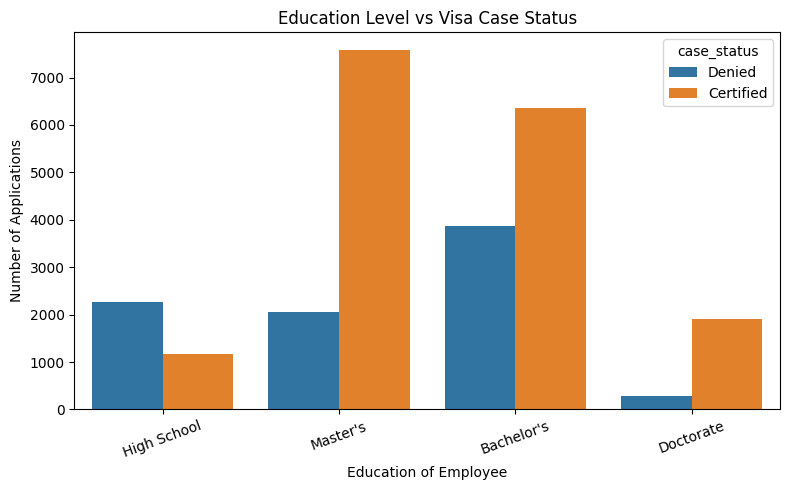

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="education_of_employee",
    hue="case_status"
)

plt.title("Education Level vs Visa Case Status")
plt.xlabel("Education of Employee")
plt.ylabel("Number of Applications")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

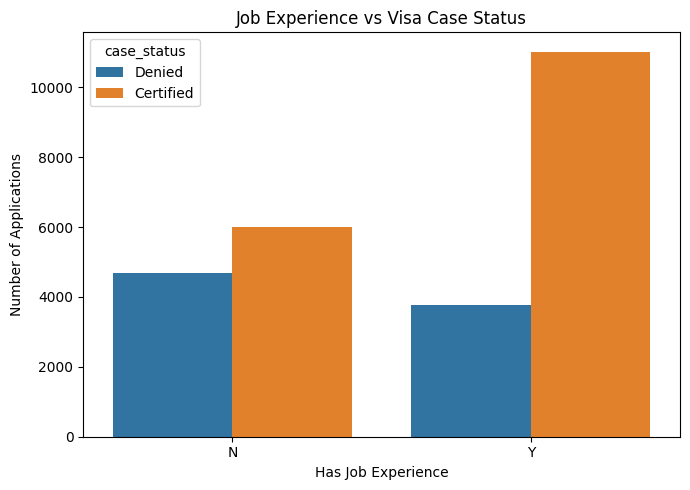

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="has_job_experience",
    hue="case_status"
)

plt.title("Job Experience vs Visa Case Status")
plt.xlabel("Has Job Experience")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

In [25]:
experience_status_rate = pd.crosstab(
    df["has_job_experience"],
    df["case_status"],
    normalize="index"
) * 100

print(experience_status_rate)

case_status         Certified     Denied
has_job_experience                      
N                   56.134108  43.865892
Y                   74.476422  25.523578


In [26]:
training_status_rate = pd.crosstab(
    df["requires_job_training"],
    df["case_status"],
    normalize="index"
) * 100

print(training_status_rate)

case_status            Certified     Denied
requires_job_training                      
N                      66.645949  33.354051
Y                      67.884941  32.115059


In [27]:
continent_status_rate = pd.crosstab(
    df["continent"],
    df["case_status"],
    normalize="index"
) * 100

print(continent_status_rate)

case_status    Certified     Denied
continent                          
Africa         72.050817  27.949183
Asia           65.310480  34.689520
Europe         79.233655  20.766345
North America  61.877278  38.122722
Oceania        63.541667  36.458333
South America  57.863850  42.136150


In [28]:
# ==========================================
# REMAINING CATEGORICAL FEATURE ANALYSIS
# ==========================================

remaining_categorical = [
    "region_of_employment",
    "unit_of_wage",
    "full_time_position"
]

for column in remaining_categorical:
    print("\n" + "=" * 60)
    print(f"{column} - Counts")
    print("=" * 60)
    print(df[column].value_counts())

    print(f"\n{column} - Certification Rate (%)")
    print(
        pd.crosstab(
            df[column],
            df["case_status"],
            normalize="index"
        ) * 100
    )


# ==========================================
# NUMERICAL FEATURE ANALYSIS
# ==========================================

numerical_columns = [
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage"
]

print("\n" + "=" * 60)
print("NUMERICAL FEATURE STATISTICS")
print("=" * 60)

print(df[numerical_columns].describe().T)


# ==========================================
# NUMERICAL FEATURES BY CASE STATUS
# ==========================================

print("\n" + "=" * 60)
print("NUMERICAL FEATURES BY CASE STATUS")
print("=" * 60)

print(
    df.groupby("case_status")[numerical_columns]
      .agg(["mean", "median", "min", "max"])
)


# ==========================================
# OUTLIER / DATA QUALITY CHECK
# ==========================================

print("\n" + "=" * 60)
print("OUTLIER / DATA QUALITY CHECK")
print("=" * 60)

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of IQR outliers:", len(outliers))


# ==========================================
# SPECIFIC DATA QUALITY CHECK
# ==========================================

print("\n" + "=" * 60)
print("INVALID / SUSPICIOUS VALUES")
print("=" * 60)

print(
    "Negative employee counts:",
    (df["no_of_employees"] < 0).sum()
)

print(
    "Establishment year < 1800:",
    (df["yr_of_estab"] < 1800).sum()
)

print(
    "Establishment year > 2026:",
    (df["yr_of_estab"] > 2026).sum()
)

print(
    "Negative wages:",
    (df["prevailing_wage"] < 0).sum()
)


region_of_employment - Counts
region_of_employment
Northeast    7195
South        7017
West         6586
Midwest      4307
Island        375
Name: count, dtype: int64

region_of_employment - Certification Rate (%)
case_status           Certified     Denied
region_of_employment                      
Island                60.266667  39.733333
Midwest               75.528210  24.471790
Northeast             62.904795  37.095205
South                 70.015676  29.984324
West                  62.253265  37.746735

unit_of_wage - Counts
unit_of_wage
Year     22962
Hour      2157
Week       272
Month       89
Name: count, dtype: int64

unit_of_wage - Certification Rate (%)
case_status   Certified     Denied
unit_of_wage                      
Hour          34.631433  65.368567
Month         61.797753  38.202247
Week          62.132353  37.867647
Year          69.885027  30.114973

full_time_position - Counts
full_time_position
Y    22773
N     2707
Name: count, dtype: int64

full_time_positi

In [29]:
region_status_rate = pd.crosstab(
    df["region_of_employment"],
    df["case_status"],
    normalize="index"
) * 100

print(region_status_rate)

case_status           Certified     Denied
region_of_employment                      
Island                60.266667  39.733333
Midwest               75.528210  24.471790
Northeast             62.904795  37.095205
South                 70.015676  29.984324
West                  62.253265  37.746735


In [30]:
# Remaining categorical feature details

for column in ["unit_of_wage", "full_time_position"]:
    print("\n" + "=" * 50)
    print(column)
    print("=" * 50)

    print("\nCounts:")
    print(df[column].value_counts())

    print("\nCertification rate (%):")
    print(
        pd.crosstab(
            df[column],
            df["case_status"],
            normalize="index"
        ) * 100
    )


unit_of_wage

Counts:
unit_of_wage
Year     22962
Hour      2157
Week       272
Month       89
Name: count, dtype: int64

Certification rate (%):
case_status   Certified     Denied
unit_of_wage                      
Hour          34.631433  65.368567
Month         61.797753  38.202247
Week          62.132353  37.867647
Year          69.885027  30.114973

full_time_position

Counts:
full_time_position
Y    22773
N     2707
Name: count, dtype: int64

Certification rate (%):
case_status         Certified     Denied
full_time_position                      
N                   68.526044  31.473956
Y                   66.583235  33.416765


In [31]:
# Numerical features by case status

print(
    df.groupby("case_status")[
        ["no_of_employees", "yr_of_estab", "prevailing_wage"]
    ].agg(["mean", "median"])
)

            no_of_employees          yr_of_estab         prevailing_wage  \
                       mean  median         mean  median            mean   
case_status                                                                
Certified       5807.018157  2147.0  1979.666765  1997.0    77293.619243   
Denied          5385.538407  2032.5  1978.893406  1997.0    68748.681580   

                       
               median  
case_status            
Certified    72486.27  
Denied       65431.46  


In [32]:
negative_employees = df[df["no_of_employees"] < 0]

print("Number of negative employee records:", len(negative_employees))
print(negative_employees[[
    "case_id",
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage",
    "case_status"
]].to_string(index=False))

Number of negative employee records: 33
  case_id  no_of_employees  yr_of_estab  prevailing_wage case_status
  EZYV246              -25         1980       39452.9900   Certified
  EZYV379              -11         2011       32506.1400      Denied
  EZYV833              -17         2002      129701.9400   Certified
 EZYV2919              -26         2005      112799.4600   Certified
 EZYV6440              -14         2013         103.9700      Denied
 EZYV6635              -26         1923        5247.3200      Denied
 EZYV7225              -25         1998      141435.9500   Certified
 EZYV7282              -14         2000       58488.5000      Denied
 EZYV7319              -26         2006      115005.6100   Certified
 EZYV7762              -11         2009       38457.5100   Certified
 EZYV9873              -26         1996       37397.0500   Certified
EZYV11494              -14         1999       27599.3500      Denied
EZYV13472              -17         2003         257.2413      D

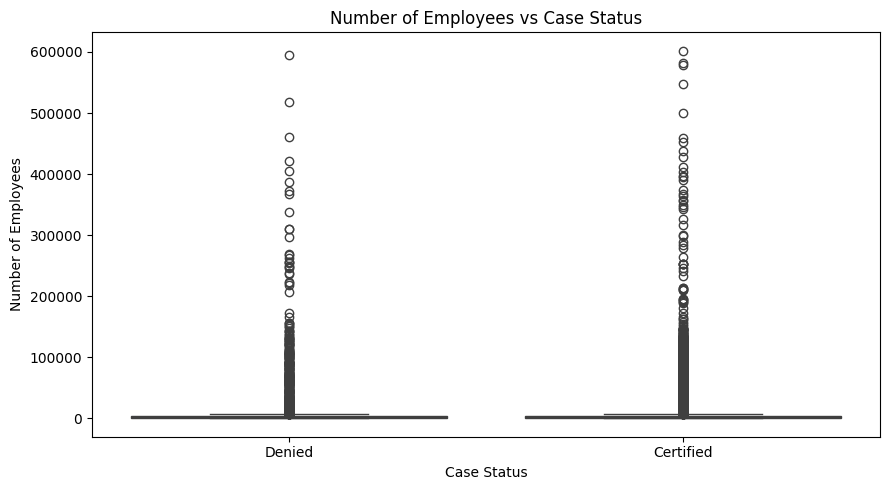

In [33]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="case_status",
    y="no_of_employees"
)

plt.title("Number of Employees vs Case Status")
plt.xlabel("Case Status")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

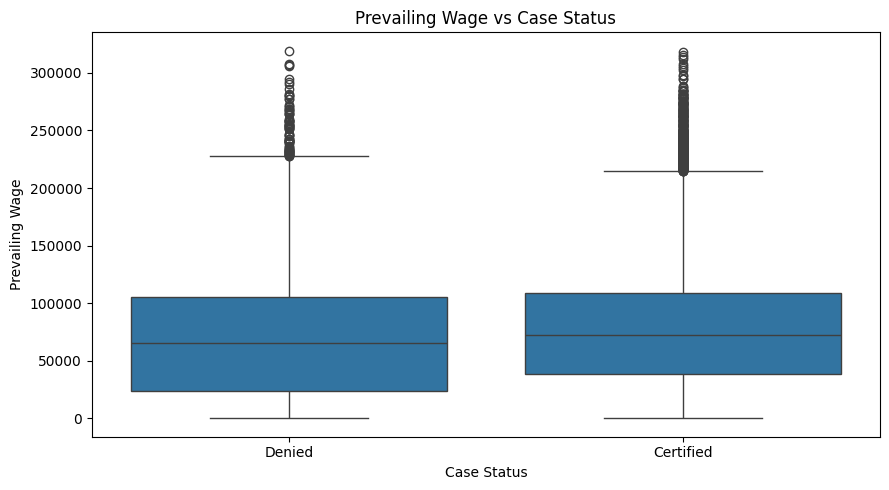

In [34]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="case_status",
    y="prevailing_wage"
)

plt.title("Prevailing Wage vs Case Status")
plt.xlabel("Case Status")
plt.ylabel("Prevailing Wage")
plt.tight_layout()
plt.show()

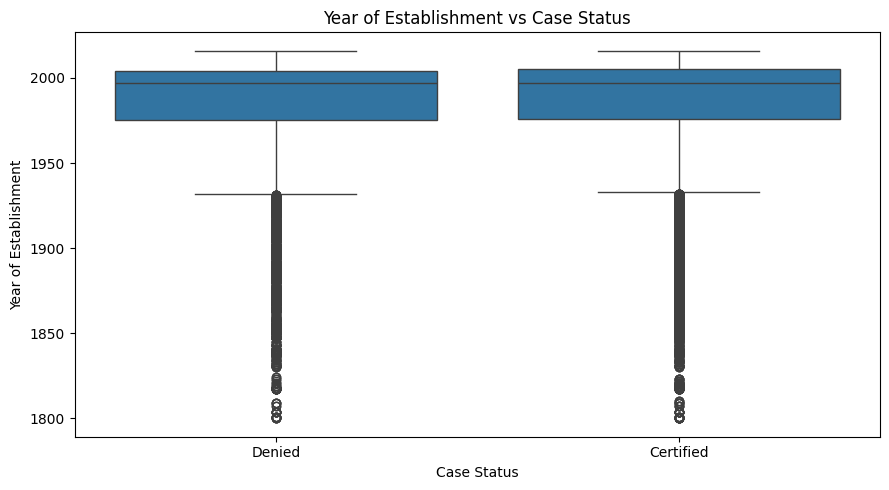

In [35]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="case_status",
    y="yr_of_estab"
)

plt.title("Year of Establishment vs Case Status")
plt.xlabel("Case Status")
plt.ylabel("Year of Establishment")
plt.tight_layout()
plt.show()

In [36]:
df_clean = df[df["no_of_employees"] >= 0].copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print(
    "Removed rows:",
    len(df) - len(df_clean)
)

Original dataset shape: (25480, 12)
Cleaned dataset shape: (25447, 12)
Removed rows: 33


In [37]:
print("Shape:", df_clean.shape)
print("\nData types:")
print(df_clean.dtypes)

Shape: (25447, 12)

Data types:
case_id                   object
continent                 object
education_of_employee     object
has_job_experience        object
requires_job_training     object
no_of_employees            int64
yr_of_estab                int64
region_of_employment      object
prevailing_wage          float64
unit_of_wage              object
full_time_position        object
case_status               object
dtype: object


In [38]:
print("Target counts:")
print(df_clean["case_status"].value_counts())

print("\nTarget percentages:")
print(df_clean["case_status"].value_counts(normalize=True) * 100)

Target counts:
case_status
Certified    17001
Denied        8446
Name: count, dtype: int64

Target percentages:
case_status
Certified    66.809447
Denied       33.190553
Name: proportion, dtype: float64


In [39]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate case IDs:", df_clean["case_id"].duplicated().sum())

Duplicate rows: 0
Duplicate case IDs: 0


In [40]:
categorical_columns = [
    "continent",
    "education_of_employee",
    "has_job_experience",
    "requires_job_training",
    "region_of_employment",
    "unit_of_wage",
    "full_time_position"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts())


continent:
continent
Asia             16840
Europe            3727
North America     3287
South America      851
Africa             550
Oceania            192
Name: count, dtype: int64

education_of_employee:
education_of_employee
Bachelor's     10220
Master's        9622
High School     3416
Doctorate       2189
Name: count, dtype: int64

has_job_experience:
has_job_experience
Y    14786
N    10661
Name: count, dtype: int64

requires_job_training:
requires_job_training
N    22498
Y     2949
Name: count, dtype: int64

region_of_employment:
region_of_employment
Northeast    7189
South        7006
West         6578
Midwest      4299
Island        375
Name: count, dtype: int64

unit_of_wage:
unit_of_wage
Year     22933
Hour      2153
Week       272
Month       89
Name: count, dtype: int64

full_time_position:
full_time_position
Y    22741
N     2706
Name: count, dtype: int64


In [41]:
numerical_columns = [
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage"
]

print(df_clean[numerical_columns].describe().T)

                   count          mean           std        min       25%  \
no_of_employees  25447.0   5674.415334  22891.842245    12.0000   1025.00   
yr_of_estab      25447.0   1979.394506     42.385932  1800.0000   1976.00   
prevailing_wage  25447.0  74468.281479  52822.177370     2.1367  34039.21   

                     50%         75%        max  
no_of_employees   2112.0    3506.500  602069.00  
yr_of_estab       1997.0    2005.000    2016.00  
prevailing_wage  70312.5  107739.505  319210.27  


In [42]:
print("Negative employees:",
      (df_clean["no_of_employees"] < 0).sum())

print("Negative wages:",
      (df_clean["prevailing_wage"] < 0).sum())

print("Invalid establishment years:",
      ((df_clean["yr_of_estab"] < 1800) |
       (df_clean["yr_of_estab"] > 2026)).sum())

Negative employees: 0
Negative wages: 0
Invalid establishment years: 0


In [43]:
print(df_clean.isnull().sum())

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64


In [44]:
print("Unique target values:")
print(df_clean["case_status"].unique())

Unique target values:
['Denied' 'Certified']


In [45]:
# Separate features and target

X = df_clean.drop(columns=["case_status", "case_id"])
y = df_clean["case_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X shape: (25447, 10)
y shape: (25447,)

Features:
['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'no_of_employees', 'yr_of_estab', 'region_of_employment', 'prevailing_wage', 'unit_of_wage', 'full_time_position']

Target:
case_status


In [46]:
print("X sample:")
display(X.head())

print("\ny sample:")
display(y.head())

X sample:


,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y



y sample:


0       Denied
1    Certified
2       Denied
3       Denied
4    Certified
Name: case_status, dtype: object

In [47]:
print("Categorical features:")
print(X.select_dtypes(include=["object"]).columns.tolist())

print("\nNumerical features:")
print(X.select_dtypes(include=["int64", "float64"]).columns.tolist())

Categorical features:
['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']

Numerical features:
['no_of_employees', 'yr_of_estab', 'prevailing_wage']


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (20357, 10)
Testing features: (5090, 10)

Training target distribution:
case_status
Certified    66.807486
Denied       33.192514
Name: proportion, dtype: float64

Testing target distribution:
case_status
Certified    66.817289
Denied       33.182711
Name: proportion, dtype: float64


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [52]:
categorical_features = [
    "continent",
    "education_of_employee",
    "has_job_experience",
    "requires_job_training",
    "region_of_employment",
    "unit_of_wage",
    "full_time_position"
]

numerical_features = [
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage"
]

print("Categorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

Categorical features: ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']
Number of categorical features: 7

Numerical features: ['no_of_employees', 'yr_of_estab', 'prevailing_wage']
Number of numerical features: 3


In [53]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [54]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

print("\nOriginal X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

Original X_train shape: (20357, 10)
Processed X_train shape: (20357, 28)

Original X_test shape: (5090, 10)
Processed X_test shape: (5090, 28)


In [55]:
print("Processed data type:", type(X_train_processed))
print("Processed data shape:", X_train_processed.shape)

print("\nFirst 5 rows:")
print(X_train_processed[:5])

Processed data type: <class 'numpy.ndarray'>
Processed data shape: (20357, 28)

First 5 rows:
[[-0.201845   -0.29083944  0.58939344  0.          1.          0.
   0.          0.          0.          0.          0.          0.
   1.          0.          1.          1.          0.          0.
   0.          0.          1.          0.          0.          0.
   0.          1.          0.          1.        ]
 [-0.16252998 -1.6101658   1.10921285  0.          1.          0.
   0.          0.          0.          0.          0.          0.
   1.          0.          1.          1.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.          1.          0.          1.        ]
 [-0.06868407 -0.22016124 -0.45099934  0.          0.          1.
   0.          0.          0.          0.          1.          0.
   0.          1.          0.          1.          0.          0.
   0.          0.          0.          1.          0.          0.
   0.       

In [68]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [59]:
y_train_encoded = y_train.map({
    "Denied": 0,
    "Certified": 1
})

y_test_encoded = y_test.map({
    "Denied": 0,
    "Certified": 1
})

print("Training target:")
print(y_train_encoded.value_counts())

print("\nTesting target:")
print(y_test_encoded.value_counts())

Training target:
case_status
1    13600
0     6757
Name: count, dtype: int64

Testing target:
case_status
1    3401
0    1689
Name: count, dtype: int64


In [60]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Logistic Regression
- Random Forest
- XGBoost
- LightGBM


In [61]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("Pipelines created successfully!")

for name in pipelines:
    print("-", name)

Pipelines created successfully!
- Logistic Regression
- Random Forest
- XGBoost
- LightGBM


In [62]:
results = []

for name, pipeline in pipelines.items():

    print(f"\nTraining {name}...")

    pipeline.fit(X_train, y_train_encoded)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test_encoded, y_pred)
    precision = precision_score(y_test_encoded, y_pred)
    recall = recall_score(y_test_encoded, y_pred)
    f1 = f1_score(y_test_encoded, y_pred)
    roc_auc = roc_auc_score(y_test_encoded, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    print(f"{name} completed.")


Training Logistic Regression...
Logistic Regression completed.

Training Random Forest...
Random Forest completed.

Training XGBoost...
XGBoost completed.

Training LightGBM...
LightGBM completed.


In [63]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
           LightGBM  0.740668   0.770752 0.870920  0.817780 0.769679
            XGBoost  0.737917   0.769632 0.867392  0.815593 0.771431
Logistic Regression  0.731238   0.760976 0.871508  0.812500 0.767984
      Random Forest  0.721022   0.764627 0.841517  0.801232 0.753137


In [64]:
best_model_name = results_df.iloc[0]["Model"]

print("Best model based on F1 Score:")
print(best_model_name)

Best model based on F1 Score:
LightGBM


In [69]:
# ==========================================
# DETAILED EVALUATION - LIGHTGBM
# ==========================================

best_pipeline = pipelines["LightGBM"]

# Predictions
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# Classification report
print("=" * 60)
print("CLASSIFICATION REPORT - LIGHTGBM")
print("=" * 60)

print(
    classification_report(
        y_test_encoded,
        y_pred,
        target_names=["Denied", "Certified"]
    )
)


# Confusion matrix
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(y_test_encoded, y_pred)

print(cm)

CLASSIFICATION REPORT - LIGHTGBM
              precision    recall  f1-score   support

      Denied       0.65      0.48      0.55      1689
   Certified       0.77      0.87      0.82      3401

    accuracy                           0.74      5090
   macro avg       0.71      0.67      0.68      5090
weighted avg       0.73      0.74      0.73      5090

CONFUSION MATRIX
[[ 808  881]
 [ 439 2962]]


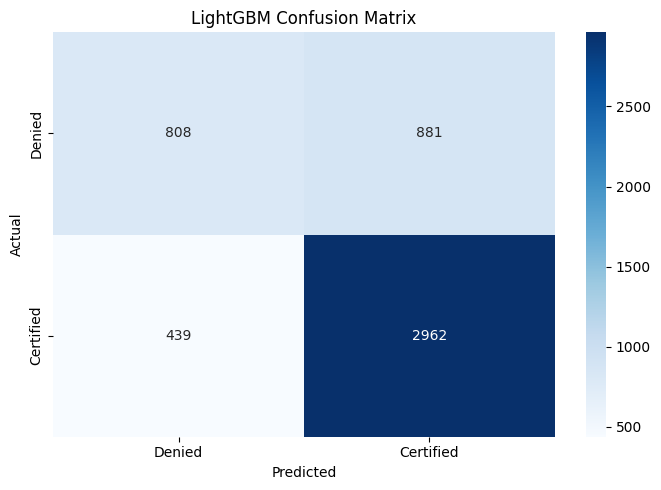

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Denied", "Certified"],
    yticklabels=["Denied", "Certified"]
)

plt.title("LightGBM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [71]:
# ==========================================
# FEATURE IMPORTANCE - LIGHTGBM
# ==========================================

fitted_preprocessor = best_pipeline.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

model = best_pipeline.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 Most Important Features:")
print(importance_df.head(20).to_string(index=False))

Top 20 Most Important Features:
                               Feature  Importance
                  num__prevailing_wage        1612
                  num__no_of_employees        1497
                      num__yr_of_estab        1135
             cat__has_job_experience_N         165
                   cat__continent_Asia         141
          cat__requires_job_training_N         133
       cat__region_of_employment_South         128
 cat__education_of_employee_Bachelor's         126
   cat__region_of_employment_Northeast         106
     cat__region_of_employment_Midwest         105
        cat__region_of_employment_West         104
          cat__continent_North America         102
                 cat__continent_Europe          98
             cat__full_time_position_N          94
cat__education_of_employee_High School          85
   cat__education_of_employee_Master's          68
  cat__education_of_employee_Doctorate          59
          cat__continent_South America          48

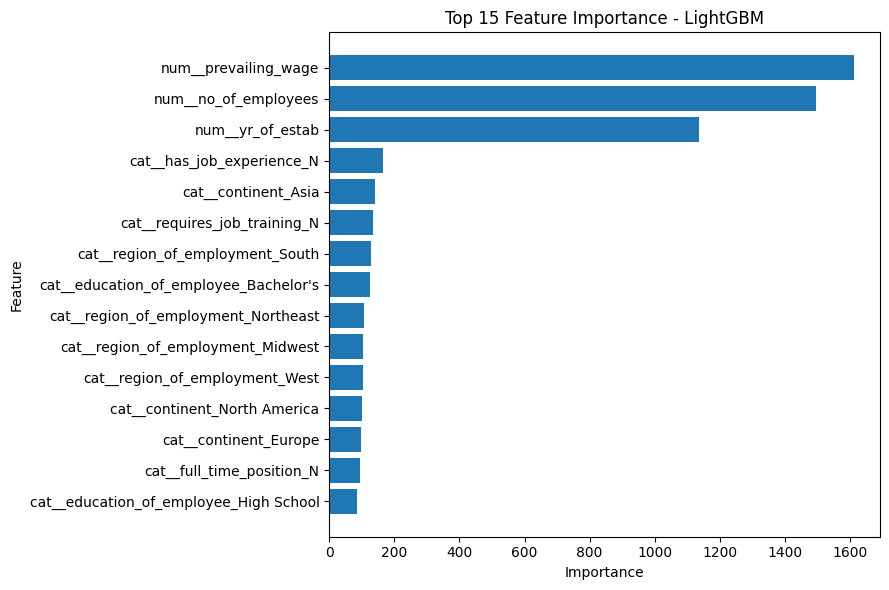

In [72]:
# ==========================================
# TOP 15 FEATURE IMPORTANCE
# ==========================================

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importance - LightGBM")
plt.tight_layout()
plt.show()

In [73]:
baseline_results = results_df.copy()

print("Baseline model results:")
print(baseline_results.to_string(index=False))

Baseline model results:
              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
           LightGBM  0.740668   0.770752 0.870920  0.817780 0.769679
            XGBoost  0.737917   0.769632 0.867392  0.815593 0.771431
Logistic Regression  0.731238   0.760976 0.871508  0.812500 0.767984
      Random Forest  0.721022   0.764627 0.841517  0.801232 0.753137


In [81]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

In [76]:
lgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

print("LightGBM tuning pipeline created successfully!")

LightGBM tuning pipeline created successfully!


In [77]:
param_distributions = {
    "model__n_estimators": randint(100, 500),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__num_leaves": randint(15, 80),
    "model__max_depth": randint(3, 12),
    "model__min_child_samples": randint(10, 100),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3)
}

print("Parameter search space created!")

Parameter search space created!


In [84]:
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV

param_distributions_fast = {
    "model__n_estimators": randint(100, 300),
    "model__learning_rate": uniform(0.03, 0.12),
    "model__num_leaves": randint(20, 60),
    "model__max_depth": randint(4, 10),
    "model__min_child_samples": randint(20, 80)
}

print("Fast parameter search space created!")

Fast parameter search space created!


In [85]:
random_search_fast = RandomizedSearchCV(
    estimator=lgbm_pipeline,
    param_distributions=param_distributions_fast,
    n_iter=8,
    scoring="f1",
    cv=2,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Fast RandomizedSearchCV created!")

Fast RandomizedSearchCV created!


In [86]:
print("Starting fast LightGBM tuning...")

random_search_fast.fit(
    X_train,
    y_train_encoded
)

print("Fast LightGBM tuning completed!")

Starting fast LightGBM tuning...
Fitting 2 folds for each of 8 candidates, totalling 16 fits
Fast LightGBM tuning completed!


In [87]:
print("=" * 60)
print("BEST PARAMETERS")
print("=" * 60)

print(random_search_fast.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_search_fast.best_score_)

BEST PARAMETERS
{'model__learning_rate': np.float64(0.03009345190092172), 'model__max_depth': 7, 'model__min_child_samples': 40, 'model__n_estimators': 260, 'model__num_leaves': 31}

Best Cross-Validation F1 Score:
0.8225435971747646


In [88]:
tuned_lgbm = random_search_fast.best_estimator_

tuned_pred = tuned_lgbm.predict(X_test)
tuned_prob = tuned_lgbm.predict_proba(X_test)[:, 1]

tuned_accuracy = accuracy_score(
    y_test_encoded,
    tuned_pred
)

tuned_precision = precision_score(
    y_test_encoded,
    tuned_pred
)

tuned_recall = recall_score(
    y_test_encoded,
    tuned_pred
)

tuned_f1 = f1_score(
    y_test_encoded,
    tuned_pred
)

tuned_auc = roc_auc_score(
    y_test_encoded,
    tuned_prob
)

print("=" * 60)
print("TUNED LIGHTGBM TEST RESULTS")
print("=" * 60)

print(f"Accuracy : {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall   : {tuned_recall:.4f}")
print(f"F1 Score : {tuned_f1:.4f}")
print(f"ROC-AUC  : {tuned_auc:.4f}")

TUNED LIGHTGBM TEST RESULTS
Accuracy : 0.7472
Precision: 0.7779
Recall   : 0.8700
F1 Score : 0.8214
ROC-AUC  : 0.7797


In [89]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Baseline LightGBM": [
        0.740668,
        0.770752,
        0.870920,
        0.817780,
        0.769679
    ],
    "Tuned LightGBM": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_auc
    ]
})

print(comparison.to_string(index=False))

   Metric  Baseline LightGBM  Tuned LightGBM
 Accuracy           0.740668        0.747151
Precision           0.770752        0.777865
   Recall           0.870920        0.870038
 F1 Score           0.817780        0.821374
  ROC-AUC           0.769679        0.779721


In [90]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions from tuned model
y_pred_tuned = random_search.predict(X_test)
y_prob_tuned = random_search.predict_proba(X_test)[:, 1]

print("=" * 60)
print("TUNED LIGHTGBM - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test_encoded,
    y_pred_tuned,
    target_names=["Denied", "Certified"]
))

print("=" * 60)
print("TUNED LIGHTGBM - CONFUSION MATRIX")
print("=" * 60)

cm_tuned = confusion_matrix(y_test_encoded, y_pred_tuned)

print(cm_tuned)

print("\n" + "=" * 60)
print("TUNED LIGHTGBM - FINAL METRICS")
print("=" * 60)

tuned_accuracy = accuracy_score(y_test_encoded, y_pred_tuned)
tuned_precision = precision_score(y_test_encoded, y_pred_tuned)
tuned_recall = recall_score(y_test_encoded, y_pred_tuned)
tuned_f1 = f1_score(y_test_encoded, y_pred_tuned)
tuned_auc = roc_auc_score(y_test_encoded, y_prob_tuned)

print(f"Accuracy  : {tuned_accuracy:.4f}")
print(f"Precision : {tuned_precision:.4f}")
print(f"Recall    : {tuned_recall:.4f}")
print(f"F1 Score  : {tuned_f1:.4f}")
print(f"ROC-AUC   : {tuned_auc:.4f}")

NotFittedError: This RandomizedSearchCV instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [91]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Best parameters obtained from the completed tuning
best_lgbm = LGBMClassifier(
    learning_rate=0.03009345190092172,
    max_depth=7,
    min_child_samples=40,
    n_estimators=260,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# Create final pipeline
final_lgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_lgbm)
])

print("Training final tuned LightGBM...")
final_lgbm_pipeline.fit(X_train, y_train_encoded)

print("Final tuned LightGBM trained successfully!")

# Predictions
y_pred_tuned = final_lgbm_pipeline.predict(X_test)
y_prob_tuned = final_lgbm_pipeline.predict_proba(X_test)[:, 1]

# Metrics
tuned_accuracy = accuracy_score(y_test_encoded, y_pred_tuned)
tuned_precision = precision_score(y_test_encoded, y_pred_tuned)
tuned_recall = recall_score(y_test_encoded, y_pred_tuned)
tuned_f1 = f1_score(y_test_encoded, y_pred_tuned)
tuned_auc = roc_auc_score(y_test_encoded, y_prob_tuned)

print("\n" + "=" * 60)
print("TUNED LIGHTGBM - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test_encoded,
    y_pred_tuned,
    target_names=["Denied", "Certified"]
))

print("=" * 60)
print("TUNED LIGHTGBM - CONFUSION MATRIX")
print("=" * 60)

cm_tuned = confusion_matrix(y_test_encoded, y_pred_tuned)
print(cm_tuned)

print("\n" + "=" * 60)
print("TUNED LIGHTGBM - FINAL METRICS")
print("=" * 60)

print(f"Accuracy  : {tuned_accuracy:.4f}")
print(f"Precision : {tuned_precision:.4f}")
print(f"Recall    : {tuned_recall:.4f}")
print(f"F1 Score  : {tuned_f1:.4f}")
print(f"ROC-AUC   : {tuned_auc:.4f}")

Training final tuned LightGBM...
Final tuned LightGBM trained successfully!

TUNED LIGHTGBM - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Denied       0.66      0.50      0.57      1689
   Certified       0.78      0.87      0.82      3401

    accuracy                           0.75      5090
   macro avg       0.72      0.68      0.69      5090
weighted avg       0.74      0.75      0.74      5090

TUNED LIGHTGBM - CONFUSION MATRIX
[[ 844  845]
 [ 442 2959]]

TUNED LIGHTGBM - FINAL METRICS
Accuracy  : 0.7472
Precision : 0.7779
Recall    : 0.8700
F1 Score  : 0.8214
ROC-AUC   : 0.7797


In [92]:
# Get the fitted preprocessor and model
fitted_preprocessor = final_lgbm_pipeline.named_steps["preprocessor"]
fitted_model = final_lgbm_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance from final tuned LightGBM
importance_values = fitted_model.feature_importances_

# Create feature importance dataframe
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("=" * 60)
print("TOP 20 FEATURE IMPORTANCE - FINAL TUNED LIGHTGBM")
print("=" * 60)

print(feature_importance_df.head(20).to_string(index=False))

TOP 20 FEATURE IMPORTANCE - FINAL TUNED LIGHTGBM
                               Feature  Importance
                  num__prevailing_wage        1749
                  num__no_of_employees        1665
                      num__yr_of_estab        1188
             cat__has_job_experience_N         290
     cat__region_of_employment_Midwest         254
       cat__region_of_employment_South         251
          cat__requires_job_training_N         250
                 cat__continent_Europe         245
             cat__full_time_position_N         236
 cat__education_of_employee_Bachelor's         232
                   cat__continent_Asia         205
          cat__continent_North America         175
cat__education_of_employee_High School         155
        cat__region_of_employment_West         153
  cat__education_of_employee_Doctorate         148
          cat__continent_South America         108
   cat__region_of_employment_Northeast          93
   cat__education_of_employee_Mas

In [93]:
# Get the fitted preprocessor and model
fitted_preprocessor = final_lgbm_pipeline.named_steps["preprocessor"]
fitted_model = final_lgbm_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance from final tuned LightGBM
importance_values = fitted_model.feature_importances_

# Create feature importance dataframe
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("=" * 60)
print("TOP 20 FEATURE IMPORTANCE - FINAL TUNED LIGHTGBM")
print("=" * 60)

print(feature_importance_df.head(20).to_string(index=False))

TOP 20 FEATURE IMPORTANCE - FINAL TUNED LIGHTGBM
                               Feature  Importance
                  num__prevailing_wage        1749
                  num__no_of_employees        1665
                      num__yr_of_estab        1188
             cat__has_job_experience_N         290
     cat__region_of_employment_Midwest         254
       cat__region_of_employment_South         251
          cat__requires_job_training_N         250
                 cat__continent_Europe         245
             cat__full_time_position_N         236
 cat__education_of_employee_Bachelor's         232
                   cat__continent_Asia         205
          cat__continent_North America         175
cat__education_of_employee_High School         155
        cat__region_of_employment_West         153
  cat__education_of_employee_Doctorate         148
          cat__continent_South America         108
   cat__region_of_employment_Northeast          93
   cat__education_of_employee_Mas

In [1]:
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.49.1


In [2]:
# Transform test data using the fitted preprocessor
X_test_processed = fitted_preprocessor.transform(X_test)

print("Processed test data shape:", X_test_processed.shape)

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(fitted_model)

print("SHAP explainer created successfully!")

NameError: name 'fitted_preprocessor' is not defined

In [3]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

print("Libraries imported successfully!")
print("SHAP version:", shap.__version__)

Libraries imported successfully!
SHAP version: 0.49.1


In [5]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("EasyVisa.csv")

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

# Remove rows with negative employee counts
df_clean = df[df["no_of_employees"] >= 0].copy()

print("Cleaned shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

# Verify cleaning
print("\nNegative employees:", 
      (df_clean["no_of_employees"] < 0).sum())

print("\nMissing values:")
print(df_clean.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'EasyVisa.csv'

In [6]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current working directory:
c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\notebook

Files in current directory:
['01_data_understanding.ipynb']


In [7]:
df = pd.read_csv("EasyVisa.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'EasyVisa.csv'

In [8]:
import os

gmaa_path = r"C:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA"

for root, dirs, files in os.walk(gmaa_path):
    for file in files:
        if file.lower() == "easyvisa.csv":
            print("FOUND:")
            print(os.path.join(root, file))

FOUND:
C:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\data\EasyVisa.csv


In [9]:
# ============================================================
# GMAA - RESTART ENVIRONMENT
# Reload data + preprocessing + final tuned LightGBM
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from lightgbm import LGBMClassifier

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

file_path = r"C:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\data\EasyVisa.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)


# ------------------------------------------------------------
# 2. CLEAN DATA
# ------------------------------------------------------------

df_clean = df.copy()

# Remove rows having negative employee count
df_clean = df_clean[df_clean["no_of_employees"] >= 0].copy()

print("Cleaned dataset shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))


# ------------------------------------------------------------
# 3. DEFINE FEATURES AND TARGET
# ------------------------------------------------------------

X = df_clean.drop(columns=["case_status", "case_id"])
y = df_clean["case_status"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


# ------------------------------------------------------------
# 4. ENCODE TARGET
# Certified = 1
# Denied = 0
# ------------------------------------------------------------

y_encoded = y.map({
    "Denied": 0,
    "Certified": 1
})

print("\nEncoded target distribution:")
print(y_encoded.value_counts())


# ------------------------------------------------------------
# 5. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


# ------------------------------------------------------------
# 6. IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ------------------------------------------------------------

categorical_features = [
    "continent",
    "education_of_employee",
    "has_job_experience",
    "requires_job_training",
    "region_of_employment",
    "unit_of_wage",
    "full_time_position"
]

numerical_features = [
    "no_of_employees",
    "yr_of_estab",
    "prevailing_wage"
]

print("\nCategorical features:", categorical_features)
print("Numerical features:", numerical_features)


# ------------------------------------------------------------
# 7. CREATE PREPROCESSOR
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("\nPreprocessor created successfully!")


# ------------------------------------------------------------
# 8. FINAL TUNED LIGHTGBM
# Best parameters obtained earlier
# ------------------------------------------------------------

final_lgbm = LGBMClassifier(
    learning_rate=0.03009345190092172,
    max_depth=7,
    min_child_samples=40,
    n_estimators=260,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

final_lgbm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", final_lgbm)
    ]
)

print("Final LightGBM pipeline created!")


# ------------------------------------------------------------
# 9. TRAIN FINAL MODEL
# ------------------------------------------------------------

print("\nTraining final tuned LightGBM...")

final_lgbm_pipeline.fit(
    X_train,
    y_train
)

print("Final tuned LightGBM trained successfully!")


# ------------------------------------------------------------
# 10. FINAL TEST PREDICTIONS
# ------------------------------------------------------------

y_pred_tuned = final_lgbm_pipeline.predict(X_test)
y_prob_tuned = final_lgbm_pipeline.predict_proba(X_test)[:, 1]


# ------------------------------------------------------------
# 11. FINAL METRICS
# ------------------------------------------------------------

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)
tuned_auc = roc_auc_score(y_test, y_prob_tuned)

print("\n" + "=" * 60)
print("FINAL TUNED LIGHTGBM RESULTS")
print("=" * 60)

print(f"Accuracy  : {tuned_accuracy:.4f}")
print(f"Precision : {tuned_precision:.4f}")
print(f"Recall    : {tuned_recall:.4f}")
print(f"F1 Score  : {tuned_f1:.4f}")
print(f"ROC-AUC   : {tuned_auc:.4f}")


# ------------------------------------------------------------
# 12. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=["Denied", "Certified"]
    )
)


# ------------------------------------------------------------
# 13. CONFUSION MATRIX
# ------------------------------------------------------------

print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(confusion_matrix(y_test, y_pred_tuned))


# ------------------------------------------------------------
# 14. GET FITTED PREPROCESSOR + MODEL
# Needed for SHAP
# ------------------------------------------------------------

fitted_preprocessor = final_lgbm_pipeline.named_steps["preprocessor"]
fitted_model = final_lgbm_pipeline.named_steps["model"]

print("\nFitted preprocessor and LightGBM model ready!")

Dataset loaded successfully!
Original dataset shape: (25480, 12)
Cleaned dataset shape: (25447, 12)
Rows removed: 33

X shape: (25447, 10)
y shape: (25447,)

Features:
['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'no_of_employees', 'yr_of_estab', 'region_of_employment', 'prevailing_wage', 'unit_of_wage', 'full_time_position']

Target distribution:
case_status
Certified    17001
Denied        8446
Name: count, dtype: int64

Encoded target distribution:
case_status
1    17001
0     8446
Name: count, dtype: int64

Training shape: (20357, 10)
Testing shape: (5090, 10)

Training target distribution:
case_status
1    13600
0     6757
Name: count, dtype: int64

Testing target distribution:
case_status
1    3401
0    1689
Name: count, dtype: int64

Categorical features: ['continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'region_of_employment', 'unit_of_wage', 'full_time_position']
Numerical features: ['no_of_employees'

In [10]:
# ============================================================
# SHAP - PREPARE PROCESSED DATA
# ============================================================

import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

# Transform test data
X_test_processed = fitted_preprocessor.transform(X_test)

print("\nProcessed test data shape:", X_test_processed.shape)


# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))

print("\nFirst 10 processed feature names:")
print(feature_names[:10])


# Convert processed data into DataFrame
X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("\nProcessed DataFrame shape:")
print(X_test_processed_df.shape)

print("\nProcessed DataFrame preview:")
print(X_test_processed_df.head())

SHAP version: 0.49.1

Processed test data shape: (5090, 28)
Number of feature names: 28

First 10 processed feature names:
['num__no_of_employees' 'num__yr_of_estab' 'num__prevailing_wage'
 'cat__continent_Africa' 'cat__continent_Asia' 'cat__continent_Europe'
 'cat__continent_North America' 'cat__continent_Oceania'
 'cat__continent_South America' "cat__education_of_employee_Bachelor's"]

Processed DataFrame shape:
(5090, 28)

Processed DataFrame preview:
       num__no_of_employees  num__yr_of_estab  num__prevailing_wage  \
16669             -0.085562          0.676724             -0.397222   
6492               0.607702          0.605759             -0.037175   
22698             -0.073896         -0.789901              0.027554   
8917              -0.164669          0.463827             -0.252392   
10346             -0.092632          0.700380             -1.403206   

       cat__continent_Africa  cat__continent_Asia  cat__continent_Europe  \
16669                    0.0          

In [11]:
# ============================================================
# SHAP TREE EXPLAINER
# ============================================================

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(fitted_model)

print("SHAP TreeExplainer created successfully!")


# Calculate SHAP values
shap_values = explainer.shap_values(X_test_processed_df)

print("SHAP values calculated successfully!")

print("SHAP value type:", type(shap_values))


# Check shape
if isinstance(shap_values, list):
    print("Number of SHAP outputs:", len(shap_values))
    print("SHAP values shape:", shap_values[1].shape)
else:
    print("SHAP values shape:", shap_values.shape)

SHAP TreeExplainer created successfully!
SHAP values calculated successfully!
SHAP value type: <class 'numpy.ndarray'>
SHAP values shape: (5090, 28)


c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [12]:
# ============================================================
# SHAP GLOBAL FEATURE IMPORTANCE
# ============================================================

# Calculate mean absolute SHAP value for every feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Sort from most important to least important
shap_importance_df = shap_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("TOP 20 SHAP FEATURE IMPORTANCE")
print("=" * 60)

print(shap_importance_df.head(20).to_string(index=False))

TOP 20 SHAP FEATURE IMPORTANCE
                               Feature  Mean_Absolute_SHAP
             cat__has_job_experience_N            0.488238
cat__education_of_employee_High School            0.400930
 cat__education_of_employee_Bachelor's            0.371072
     cat__region_of_employment_Midwest            0.173964
                 cat__continent_Europe            0.160031
       cat__region_of_employment_South            0.124329
                  num__prevailing_wage            0.103684
        cat__region_of_employment_West            0.099145
   cat__education_of_employee_Master's            0.092845
  cat__education_of_employee_Doctorate            0.080666
                cat__unit_of_wage_Hour            0.069178
                  num__no_of_employees            0.068576
             cat__full_time_position_N            0.066183
                      num__yr_of_estab            0.054723
                cat__unit_of_wage_Year            0.054482
   cat__region_of_employm

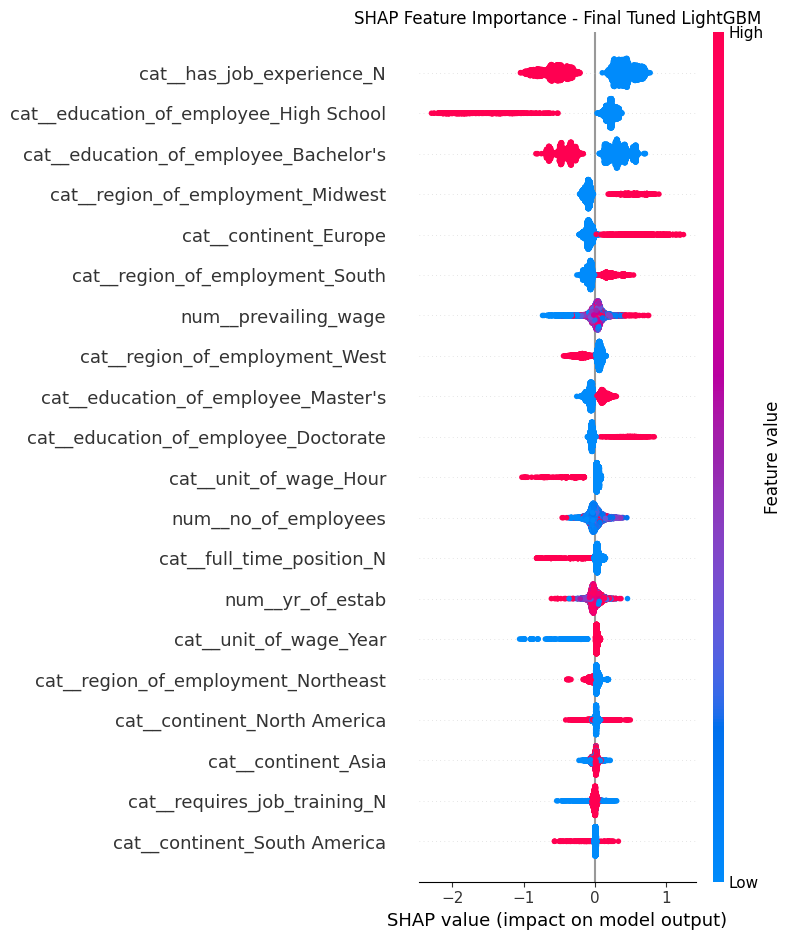

In [13]:
# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test_processed_df,
    max_display=20,
    show=False
)

plt.title("SHAP Feature Importance - Final Tuned LightGBM")
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# GMAA - FAIRNESS ANALYSIS
# Group-wise Model Performance
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create evaluation dataframe
fairness_df = X_test.copy()

fairness_df["actual"] = y_test.values
fairness_df["predicted"] = y_pred_tuned

# Convert predictions to readable labels
fairness_df["actual_label"] = fairness_df["actual"].map({
    0: "Denied",
    1: "Certified"
})

fairness_df["predicted_label"] = fairness_df["predicted"].map({
    0: "Denied",
    1: "Certified"
})

print("Fairness evaluation dataset created successfully!")
print("Shape:", fairness_df.shape)

Fairness evaluation dataset created successfully!
Shape: (5090, 14)


In [17]:
# ============================================================
# GROUP-WISE FAIRNESS METRICS FUNCTION
# ============================================================

def calculate_group_metrics(df, group_column):
    
    results = []
    
    for group in df[group_column].unique():
        
        group_data = df[df[group_column] == group]
        
        y_true_group = group_data["actual"]
        y_pred_group = group_data["predicted"]
        
        results.append({
            "Group": group,
            "Samples": len(group_data),
            "Accuracy": accuracy_score(
                y_true_group,
                y_pred_group
            ),
            "Precision": precision_score(
                y_true_group,
                y_pred_group,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true_group,
                y_pred_group,
                zero_division=0
            ),
            "F1 Score": f1_score(
                y_true_group,
                y_pred_group,
                zero_division=0
            )
        })
    
    return pd.DataFrame(results)

In [16]:
# ============================================================
# FAIRNESS: JOB EXPERIENCE
# ============================================================

experience_fairness = calculate_group_metrics(
    fairness_df,
    "has_job_experience"
)

print("=" * 70)
print("FAIRNESS ANALYSIS - JOB EXPERIENCE")
print("=" * 70)

print(experience_fairness.to_string(index=False))

# ============================================================
# FAIRNESS: EDUCATION
# ============================================================

education_fairness = calculate_group_metrics(
    fairness_df,
    "education_of_employee"
)

print("=" * 70)
print("FAIRNESS ANALYSIS - EDUCATION")
print("=" * 70)

print(education_fairness.to_string(index=False))
# ============================================================
# FAIRNESS: CONTINENT
# ============================================================

continent_fairness = calculate_group_metrics(
    fairness_df,
    "continent"
)

print("=" * 70)
print("FAIRNESS ANALYSIS - CONTINENT")
print("=" * 70)

print(continent_fairness.to_string(index=False))

# ============================================================
# FAIRNESS: REGION OF EMPLOYMENT
# ============================================================

region_fairness = calculate_group_metrics(
    fairness_df,
    "region_of_employment"
)

print("=" * 70)
print("FAIRNESS ANALYSIS - REGION OF EMPLOYMENT")
print("=" * 70)

print(region_fairness.to_string(index=False))

# ============================================================
# PREDICTED CERTIFICATION RATE BY GROUP
# ============================================================

def calculate_prediction_rates(df, group_column):
    
    result = df.groupby(group_column).agg(
        Total=("predicted", "count"),
        Predicted_Certified=("predicted", "sum"),
        Actual_Certified=("actual", "sum")
    ).reset_index()
    
    result["Predicted_Certification_Rate"] = (
        result["Predicted_Certified"] / result["Total"]
    )
    
    result["Actual_Certification_Rate"] = (
        result["Actual_Certified"] / result["Total"]
    )
    
    result["Difference"] = (
        result["Predicted_Certification_Rate"]
        - result["Actual_Certification_Rate"]
    )
    
    return result


print("=" * 70)
print("PREDICTED VS ACTUAL CERTIFICATION RATE")
print("=" * 70)

print("\n--- By Job Experience ---")
print(
    calculate_prediction_rates(
        fairness_df,
        "has_job_experience"
    ).to_string(index=False)
)

print("\n--- By Education ---")
print(
    calculate_prediction_rates(
        fairness_df,
        "education_of_employee"
    ).to_string(index=False)
)

print("\n--- By Continent ---")
print(
    calculate_prediction_rates(
        fairness_df,
        "continent"
    ).to_string(index=False)
)

print("\n--- By Employment Region ---")
print(
    calculate_prediction_rates(
        fairness_df,
        "region_of_employment"
    ).to_string(index=False)
)


FAIRNESS ANALYSIS - JOB EXPERIENCE
Group  Samples  Accuracy  Precision   Recall  F1 Score
    N     2124  0.684557   0.695823 0.756641  0.724959
    Y     2966  0.803102   0.822014 0.942704  0.878232
FAIRNESS ANALYSIS - EDUCATION
      Group  Samples  Accuracy  Precision   Recall  F1 Score
   Master's     1919  0.794685   0.807078 0.961905  0.877716
 Bachelor's     2084  0.711612   0.740741 0.856089  0.794249
High School      653  0.692190   0.493671 0.195000  0.279570
  Doctorate      434  0.866359   0.866359 1.000000  0.928395
FAIRNESS ANALYSIS - CONTINENT
        Group  Samples  Accuracy  Precision   Recall  F1 Score
         Asia     3339  0.743037   0.767118 0.865803  0.813478
North America      651  0.718894   0.726141 0.872818  0.792752
       Europe      756  0.854497   0.887367 0.941842  0.913793
South America      179  0.648045   0.643411 0.830000  0.724891
       Africa      115  0.808696   0.855556 0.895349  0.875000
      Oceania       50  0.640000   0.735294 0.735294  0.7

In [20]:
# ============================================================
# GMAA - FAIRNESS ANALYSIS
# FINAL TUNED LIGHTGBM
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 70)
print("GMAA - FAIRNESS ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Generate predictions using FINAL tuned LightGBM
# ------------------------------------------------------------

y_pred_final = final_lgbm_pipeline.predict(X_test)

print("\nPredictions generated successfully!")
print("Number of predictions:", len(y_pred_final))


# ------------------------------------------------------------
# 2. Make sure actual target is encoded correctly
# ------------------------------------------------------------

# y_test contains:
# "Certified" / "Denied"
#
# Our model uses:
# Certified = 1
# Denied = 0

if y_test.dtype == "object":

    y_test_actual = y_test.map({
        "Denied": 0,
        "Certified": 1
    })

else:

    y_test_actual = y_test.copy()


print("\nActual target prepared successfully!")

print(
    "Actual target distribution:"
)
print(y_test_actual.value_counts())


# ------------------------------------------------------------
# 3. Create fairness dataframe
# ------------------------------------------------------------

fairness_df = X_test.copy()

fairness_df["actual"] = y_test_actual.values

fairness_df["predicted"] = y_pred_final


print("\nFairness dataframe created successfully!")
print("Shape:", fairness_df.shape)


# ------------------------------------------------------------
# 4. Function to calculate group metrics
# ------------------------------------------------------------

def calculate_group_metrics(df, group_column):

    results = []

    for group in sorted(df[group_column].unique()):

        group_data = df[
            df[group_column] == group
        ]

        y_true_group = group_data["actual"]
        y_pred_group = group_data["predicted"]

        results.append({

            "Group": group,

            "Samples": len(group_data),

            "Accuracy": accuracy_score(
                y_true_group,
                y_pred_group
            ),

            "Precision": precision_score(
                y_true_group,
                y_pred_group,
                zero_division=0
            ),

            "Recall": recall_score(
                y_true_group,
                y_pred_group,
                zero_division=0
            ),

            "F1 Score": f1_score(
                y_true_group,
                y_pred_group,
                zero_division=0
            )
        })

    return pd.DataFrame(results)


# ------------------------------------------------------------
# 5. JOB EXPERIENCE FAIRNESS
# ------------------------------------------------------------

job_experience_fairness = calculate_group_metrics(
    fairness_df,
    "has_job_experience"
)

print("\n" + "=" * 70)
print("FAIRNESS ANALYSIS - JOB EXPERIENCE")
print("=" * 70)

print(
    job_experience_fairness.to_string(index=False)
)


# ------------------------------------------------------------
# 6. EDUCATION FAIRNESS
# ------------------------------------------------------------

education_fairness = calculate_group_metrics(
    fairness_df,
    "education_of_employee"
)

print("\n" + "=" * 70)
print("FAIRNESS ANALYSIS - EDUCATION")
print("=" * 70)

print(
    education_fairness.to_string(index=False)
)


# ------------------------------------------------------------
# 7. CONTINENT FAIRNESS
# ------------------------------------------------------------

continent_fairness = calculate_group_metrics(
    fairness_df,
    "continent"
)

print("\n" + "=" * 70)
print("FAIRNESS ANALYSIS - CONTINENT")
print("=" * 70)

print(
    continent_fairness.to_string(index=False)
)


# ------------------------------------------------------------
# 8. REGION FAIRNESS
# ------------------------------------------------------------

region_fairness = calculate_group_metrics(
    fairness_df,
    "region_of_employment"
)

print("\n" + "=" * 70)
print("FAIRNESS ANALYSIS - REGION OF EMPLOYMENT")
print("=" * 70)

print(
    region_fairness.to_string(index=False)
)


# ------------------------------------------------------------
# 9. F1 DISPARITY
# ------------------------------------------------------------

def calculate_f1_disparity(results_df):

    maximum_f1 = results_df["F1 Score"].max()

    minimum_f1 = results_df["F1 Score"].min()

    disparity = maximum_f1 - minimum_f1

    return disparity


print("\n" + "=" * 70)
print("FAIRNESS DISPARITY SUMMARY")
print("=" * 70)

print(
    "Job Experience F1 disparity :",
    round(
        calculate_f1_disparity(
            job_experience_fairness
        ),
        4
    )
)

print(
    "Education F1 disparity      :",
    round(
        calculate_f1_disparity(
            education_fairness
        ),
        4
    )
)

print(
    "Continent F1 disparity      :",
    round(
        calculate_f1_disparity(
            continent_fairness
        ),
        4
    )
)

print(
    "Region F1 disparity         :",
    round(
        calculate_f1_disparity(
            region_fairness
        ),
        4
    )
)


print("\n" + "=" * 70)
print("FAIRNESS ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 70)

GMAA - FAIRNESS ANALYSIS

Predictions generated successfully!
Number of predictions: 5090

Actual target prepared successfully!
Actual target distribution:
case_status
1    3401
0    1689
Name: count, dtype: int64

Fairness dataframe created successfully!
Shape: (5090, 12)

FAIRNESS ANALYSIS - JOB EXPERIENCE
Group  Samples  Accuracy  Precision   Recall  F1 Score
    N     2124  0.684557   0.695823 0.756641  0.724959
    Y     2966  0.803102   0.822014 0.942704  0.878232

FAIRNESS ANALYSIS - EDUCATION
      Group  Samples  Accuracy  Precision   Recall  F1 Score
 Bachelor's     2084  0.711612   0.740741 0.856089  0.794249
  Doctorate      434  0.866359   0.866359 1.000000  0.928395
High School      653  0.692190   0.493671 0.195000  0.279570
   Master's     1919  0.794685   0.807078 0.961905  0.877716

FAIRNESS ANALYSIS - CONTINENT
        Group  Samples  Accuracy  Precision   Recall  F1 Score
       Africa      115  0.808696   0.855556 0.895349  0.875000
         Asia     3339  0.743037

GMAA - MODEL CONFIDENCE ANALYSIS

Prediction probabilities generated successfully!
Number of probabilities: 5090

Confidence dataframe created successfully!

First 10 predictions:
       actual  predicted  probability_certified  confidence
16669       1          1               0.628534    0.628534
6492        1          1               0.731117    0.731117
22698       0          1               0.812066    0.812066
8917        1          1               0.645231    0.645231
10346       0          0               0.358920    0.641080
7738        1          1               0.778047    0.778047
1999        1          0               0.404397    0.595603
12504       0          0               0.363813    0.636187
7544        0          0               0.373462    0.626538
17703       1          1               0.576078    0.576078

CONFIDENCE STATISTICS
count    5090.000000
mean        0.745387
std         0.127134
min         0.500426
25%         0.644661
50%         0.736917
75%        

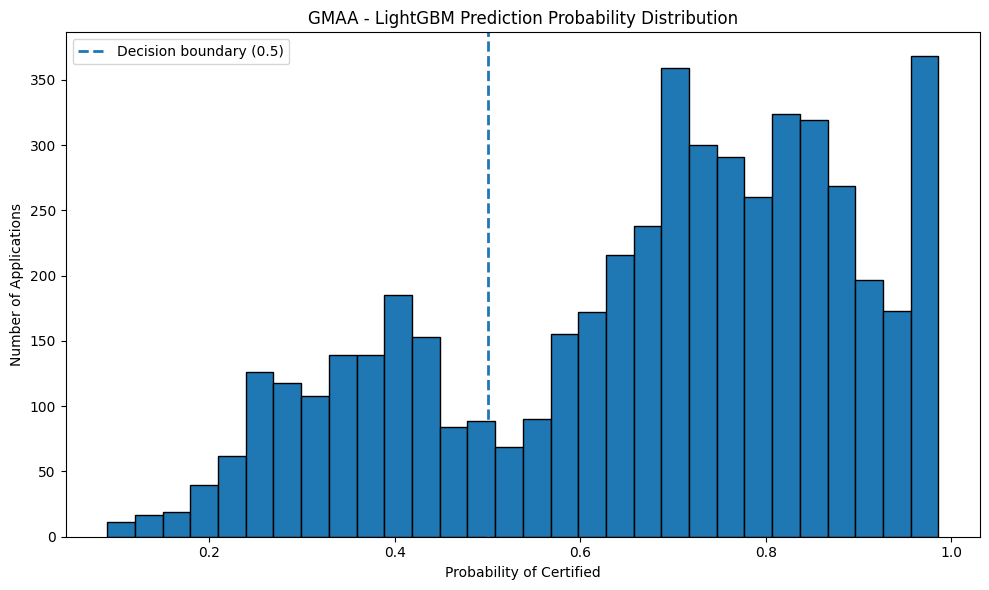

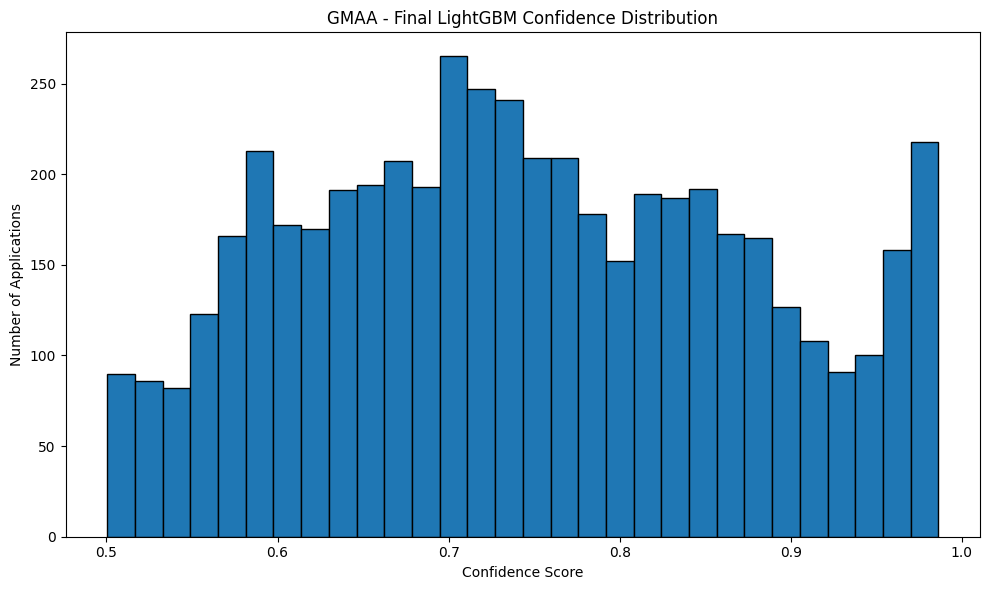


CONFIDENCE ANALYSIS COMPLETED!


In [21]:
# ============================================================
# GMAA - CONFIDENCE ANALYSIS
# FINAL TUNED LIGHTGBM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("GMAA - MODEL CONFIDENCE ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Get prediction probabilities
# ------------------------------------------------------------

y_prob_final = final_lgbm_pipeline.predict_proba(X_test)[:, 1]

print("\nPrediction probabilities generated successfully!")
print("Number of probabilities:", len(y_prob_final))


# ------------------------------------------------------------
# 2. Convert probability into confidence
# ------------------------------------------------------------

# For binary classification:
# Probability close to 0 or 1 = more confident
# Probability close to 0.5 = less confident

confidence_scores = np.maximum(
    y_prob_final,
    1 - y_prob_final
)


# ------------------------------------------------------------
# 3. Create confidence dataframe
# ------------------------------------------------------------

confidence_df = X_test.copy()

confidence_df["actual"] = y_test_actual.values

confidence_df["predicted"] = y_pred_final

confidence_df["probability_certified"] = y_prob_final

confidence_df["confidence"] = confidence_scores


print("\nConfidence dataframe created successfully!")

print("\nFirst 10 predictions:")
print(
    confidence_df[
        [
            "actual",
            "predicted",
            "probability_certified",
            "confidence"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# 4. Basic confidence statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONFIDENCE STATISTICS")
print("=" * 70)

print(
    confidence_df["confidence"].describe()
)


# ------------------------------------------------------------
# 5. Probability statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PREDICTION PROBABILITY STATISTICS")
print("=" * 70)

print(
    confidence_df["probability_certified"].describe()
)


# ------------------------------------------------------------
# 6. Find most uncertain predictions
# ------------------------------------------------------------

most_uncertain = confidence_df.sort_values(
    by="confidence",
    ascending=True
).head(20)


print("\n" + "=" * 70)
print("20 MOST UNCERTAIN PREDICTIONS")
print("=" * 70)

print(
    most_uncertain[
        [
            "actual",
            "predicted",
            "probability_certified",
            "confidence"
        ]
    ].to_string()
)


# ------------------------------------------------------------
# 7. Plot probability distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    y_prob_final,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Decision boundary (0.5)"
)

plt.xlabel("Probability of Certified")
plt.ylabel("Number of Applications")
plt.title(
    "GMAA - LightGBM Prediction Probability Distribution"
)

plt.legend()
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 8. Plot confidence distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    confidence_scores,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Confidence Score")
plt.ylabel("Number of Applications")
plt.title(
    "GMAA - Final LightGBM Confidence Distribution"
)

plt.tight_layout()

plt.show()


print("\n" + "=" * 70)
print("CONFIDENCE ANALYSIS COMPLETED!")
print("=" * 70)

In [22]:
# ============================================================
# GMAA - HUMAN REVIEW THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import accuracy_score, f1_score

print("=" * 70)
print("GMAA - HUMAN REVIEW THRESHOLD ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Make sure required variables exist
# ------------------------------------------------------------

print("\nTotal test applications:", len(y_test_actual))

# Probability already calculated
probability = y_prob_final

# Actual labels
actual = y_test_actual.values

# ------------------------------------------------------------
# Test different uncertainty bands
# ------------------------------------------------------------

thresholds = [
    (0.45, 0.55),
    (0.40, 0.60),
    (0.35, 0.65),
    (0.30, 0.70)
]

results = []

for lower, upper in thresholds:

    # Human review if probability falls inside the band
    review_mask = (
        (probability >= lower) &
        (probability <= upper)
    )

    automatic_mask = ~review_mask

    review_count = review_mask.sum()
    automatic_count = automatic_mask.sum()

    review_percentage = (
        review_count / len(probability)
    ) * 100

    automatic_percentage = (
        automatic_count / len(probability)
    ) * 100

    # Accuracy of automatic predictions
    if automatic_count > 0:

        automatic_predictions = (
            probability[automatic_mask] >= 0.5
        ).astype(int)

        automatic_accuracy = accuracy_score(
            actual[automatic_mask],
            automatic_predictions
        )

        automatic_f1 = f1_score(
            actual[automatic_mask],
            automatic_predictions,
            zero_division=0
        )

    else:

        automatic_accuracy = np.nan
        automatic_f1 = np.nan

    results.append({

        "Review Lower": lower,

        "Review Upper": upper,

        "Human Review Cases": review_count,

        "Review %": round(
            review_percentage, 2
        ),

        "Automatic Cases": automatic_count,

        "Automatic %": round(
            automatic_percentage, 2
        ),

        "Automatic Accuracy": round(
            automatic_accuracy, 4
        ),

        "Automatic F1": round(
            automatic_f1, 4
        )
    })


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

threshold_results = pd.DataFrame(results)

print("\n" + "=" * 70)
print("HUMAN REVIEW THRESHOLD COMPARISON")
print("=" * 70)

print(
    threshold_results.to_string(index=False)
)


# ------------------------------------------------------------
# Find most suitable threshold based on automatic accuracy
# ------------------------------------------------------------

best_threshold_row = threshold_results.loc[
    threshold_results["Automatic Accuracy"].idxmax()
]

print("\n" + "=" * 70)
print("BEST THRESHOLD CANDIDATE")
print("=" * 70)

print(best_threshold_row.to_string())


print("\nThreshold analysis completed successfully!")

GMAA - HUMAN REVIEW THRESHOLD ANALYSIS

Total test applications: 5090

HUMAN REVIEW THRESHOLD COMPARISON
 Review Lower  Review Upper  Human Review Cases  Review %  Automatic Cases  Automatic %  Automatic Accuracy  Automatic F1
         0.45          0.55                 265      5.21             4825        94.79              0.7664        0.8386
         0.40          0.60                 782     15.36             4308        84.64              0.7883        0.8596
         0.35          0.65                1343     26.39             3747        73.61              0.8108        0.8795
         0.30          0.70                1964     38.59             3126        61.41              0.8340        0.8986

BEST THRESHOLD CANDIDATE
Review Lower             0.3000
Review Upper             0.7000
Human Review Cases    1964.0000
Review %                38.5900
Automatic Cases       3126.0000
Automatic %             61.4100
Automatic Accuracy       0.8340
Automatic F1             0.8986

Th

In [23]:
# ============================================================
# GMAA - FINAL DECISION ENGINE
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("GMAA - FINAL DECISION ENGINE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check that the final model exists and is fitted
# ------------------------------------------------------------

if "final_lgbm_pipeline" not in globals():
    raise NameError(
        "final_lgbm_pipeline is not available. "
        "Please run the cell where the final tuned LightGBM was trained."
    )

print("Final LightGBM pipeline found successfully!")

# ------------------------------------------------------------
# 2. Define Human Review thresholds
# ------------------------------------------------------------

REVIEW_LOWER = 0.30
REVIEW_UPPER = 0.70

print(f"Human Review Range: {REVIEW_LOWER:.2f} - {REVIEW_UPPER:.2f}")

# ------------------------------------------------------------
# 3. Generate prediction probabilities
# ------------------------------------------------------------

y_probability = final_lgbm_pipeline.predict_proba(X_test)[:, 1]

print(f"Prediction probabilities generated: {len(y_probability)}")

# ------------------------------------------------------------
# 4. Generate model predictions
# ------------------------------------------------------------

y_prediction = (y_probability >= 0.50).astype(int)

# ------------------------------------------------------------
# 5. Calculate confidence
# ------------------------------------------------------------
# Confidence = distance from 0.5 decision boundary.
#
# Example:
# Probability = 0.82 → Confidence = 0.82
# Probability = 0.18 → Confidence = 0.82
# Probability = 0.51 → Confidence = 0.51

confidence = np.maximum(y_probability, 1 - y_probability)

# ------------------------------------------------------------
# 6. Apply GMAA Human Review Logic
# ------------------------------------------------------------

decision = []

for prob in y_probability:

    if REVIEW_LOWER < prob < REVIEW_UPPER:
        decision.append("HUMAN REVIEW")
    
    elif prob >= REVIEW_UPPER:
        decision.append("AUTOMATIC - CERTIFIED")
    
    else:
        decision.append("AUTOMATIC - DENIED")

# ------------------------------------------------------------
# 7. Create final GMAA decision dataframe
# ------------------------------------------------------------

gmaa_results = X_test.copy()

gmaa_results["actual_status"] = np.where(
    y_test.values == 1,
    "Certified",
    "Denied"
)

gmaa_results["predicted_status"] = np.where(
    y_prediction == 1,
    "Certified",
    "Denied"
)

gmaa_results["probability_certified"] = y_probability

gmaa_results["confidence"] = confidence

gmaa_results["gmaa_decision"] = decision

# ------------------------------------------------------------
# 8. Display summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GMAA DECISION SUMMARY")
print("=" * 70)

print(
    gmaa_results["gmaa_decision"]
    .value_counts()
)

# ------------------------------------------------------------
# 9. Calculate percentages
# ------------------------------------------------------------

decision_counts = gmaa_results["gmaa_decision"].value_counts()

total = len(gmaa_results)

print("\nDecision Percentages:")

for decision_name, count in decision_counts.items():
    percentage = (count / total) * 100
    print(f"{decision_name:25s}: {count:5d} ({percentage:.2f}%)")

# ------------------------------------------------------------
# 10. Show sample results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE GMAA RESULTS")
print("=" * 70)

display(
    gmaa_results[
        [
            "actual_status",
            "predicted_status",
            "probability_certified",
            "confidence",
            "gmaa_decision"
        ]
    ].head(10)
)

print("\n" + "=" * 70)
print("FINAL DECISION ENGINE CREATED SUCCESSFULLY!")
print("=" * 70)

GMAA - FINAL DECISION ENGINE
Final LightGBM pipeline found successfully!
Human Review Range: 0.30 - 0.70
Prediction probabilities generated: 5090

GMAA DECISION SUMMARY
gmaa_decision
AUTOMATIC - CERTIFIED    2728
HUMAN REVIEW             1964
AUTOMATIC - DENIED        398
Name: count, dtype: int64

Decision Percentages:
AUTOMATIC - CERTIFIED    :  2728 (53.60%)
HUMAN REVIEW             :  1964 (38.59%)
AUTOMATIC - DENIED       :   398 (7.82%)

SAMPLE GMAA RESULTS


,actual_status,predicted_status,probability_certified,confidence,gmaa_decision
16669,Certified,Certified,0.628534,0.628534,HUMAN REVIEW
6492,Certified,Certified,0.731117,0.731117,AUTOMATIC - CERTIFIED
22698,Denied,Certified,0.812066,0.812066,AUTOMATIC - CERTIFIED
8917,Certified,Certified,0.645231,0.645231,HUMAN REVIEW
10346,Denied,Denied,0.358920,0.641080,HUMAN REVIEW
7738,Certified,Certified,0.778047,0.778047,AUTOMATIC - CERTIFIED
1999,Certified,Denied,0.404397,0.595603,HUMAN REVIEW
12504,Denied,Denied,0.363813,0.636187,HUMAN REVIEW
7544,Denied,Denied,0.373462,0.626538,HUMAN REVIEW
17703,Certified,Certified,0.576078,0.576078,HUMAN REVIEW



FINAL DECISION ENGINE CREATED SUCCESSFULLY!


GMAA - INDIVIDUAL APPLICATION SHAP EXPLANATION
Required model and test data found!
Fitted preprocessor found!
Fitted LightGBM model found!
Processed test data shape: (5090, 28)
SHAP TreeExplainer created successfully!
SHAP values calculated successfully!
SHAP shape: (5090, 28)

Individual explanation function created successfully!

GMAA INDIVIDUAL APPLICATION RESULT
Application Index : 16669
Prediction        : Certified
Probability       : 0.6285 (62.85%)
Confidence        : 0.6285 (62.85%)
GMAA Decision     : HUMAN REVIEW

⚠ HUMAN REVIEW REQUIRED
Reason: The prediction probability is between 0.30 and 0.70.
The model is not sufficiently decisive, so a human should review this application.

----------------------------------------------------------------------
APPLICATION DETAILS
----------------------------------------------------------------------


c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,16669
continent,Asia
education_of_employee,Master's
has_job_experience,N
requires_job_training,N
no_of_employees,3675
yr_of_estab,2008
region_of_employment,Northeast
prevailing_wage,53517.96
unit_of_wage,Year
full_time_position,N



----------------------------------------------------------------------
TOP 5 EXPLANATION FEATURES
----------------------------------------------------------------------


,Feature,SHAP_Value,Absolute_SHAP
13,cat__has_job_experience_N,-0.710831,0.710831
9,cat__education_of_employee_Bachelor's,0.505924,0.505924
11,cat__education_of_employee_High School,0.223418,0.223418
26,cat__full_time_position_N,-0.167432,0.167432
5,cat__continent_Europe,-0.145341,0.145341



----------------------------------------------------------------------
FACTORS SUPPORTING CERTIFIED
----------------------------------------------------------------------


,Feature,SHAP_Value
9,cat__education_of_employee_Bachelor's,0.505924
11,cat__education_of_employee_High School,0.223418
12,cat__education_of_employee_Master's,0.127579
21,cat__region_of_employment_West,0.072586
1,num__yr_of_estab,0.070470



----------------------------------------------------------------------
FACTORS SUPPORTING DENIED
----------------------------------------------------------------------


,Feature,SHAP_Value
13,cat__has_job_experience_N,-0.710831
26,cat__full_time_position_N,-0.167432
5,cat__continent_Europe,-0.145341
19,cat__region_of_employment_Northeast,-0.139991
18,cat__region_of_employment_Midwest,-0.111900



----------------------------------------------------------------------
SHAP WATERFALL EXPLANATION
----------------------------------------------------------------------


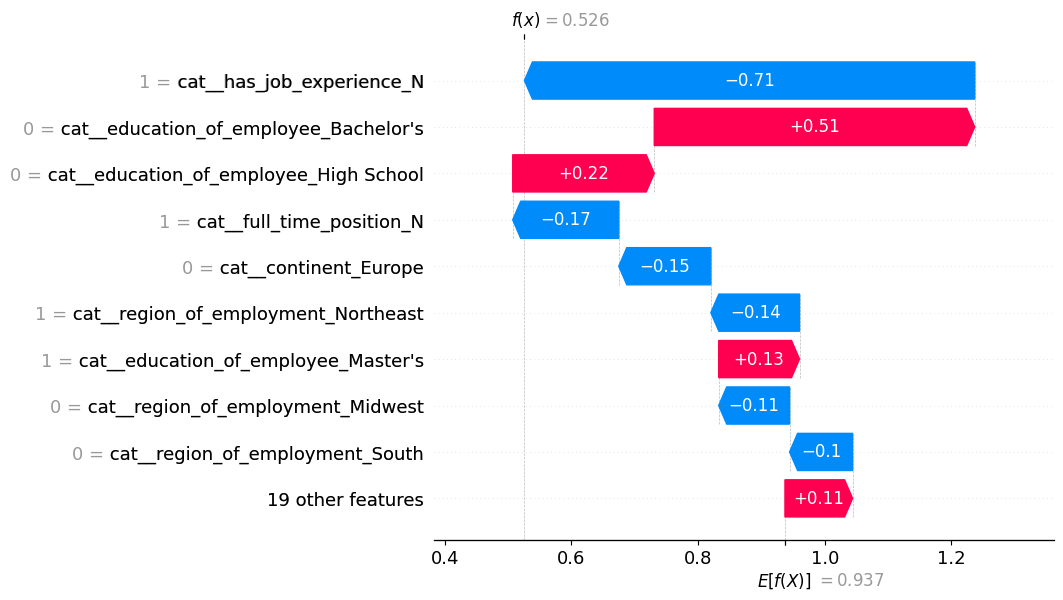


INDIVIDUAL APPLICATION EXPLANATION COMPLETED!


In [24]:
# ============================================================
# GMAA - INDIVIDUAL APPLICATION EXPLANATION
# ============================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

print("=" * 70)
print("GMAA - INDIVIDUAL APPLICATION SHAP EXPLANATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required objects
# ------------------------------------------------------------

required_objects = [
    "final_lgbm_pipeline",
    "X_test",
    "y_test"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing required objects: {missing_objects}. "
        "Please run the Final Decision Engine cell first."
    )

print("Required model and test data found!")

# ------------------------------------------------------------
# 2. Get fitted preprocessor and LightGBM model
# ------------------------------------------------------------

fitted_preprocessor = final_lgbm_pipeline.named_steps["preprocessor"]
fitted_model = final_lgbm_pipeline.named_steps["model"]

print("Fitted preprocessor found!")
print("Fitted LightGBM model found!")

# ------------------------------------------------------------
# 3. Transform test data
# ------------------------------------------------------------

X_test_processed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed test data shape:", X_test_processed_df.shape)

# ------------------------------------------------------------
# 4. Create SHAP explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(fitted_model)

print("SHAP TreeExplainer created successfully!")

# ------------------------------------------------------------
# 5. Calculate SHAP values
# ------------------------------------------------------------

shap_values = explainer.shap_values(X_test_processed_df)

# LightGBM + SHAP versions can return either:
#   ndarray
# or
#   list of ndarrays

if isinstance(shap_values, list):
    shap_values_positive = shap_values[1]
else:
    shap_values_positive = shap_values

print("SHAP values calculated successfully!")
print("SHAP shape:", shap_values_positive.shape)

# ------------------------------------------------------------
# 6. Function for explaining ONE application
# ------------------------------------------------------------

def explain_gmaa_application(test_position=0):

    # --------------------------------------------------------
    # Validate position
    # --------------------------------------------------------

    if test_position < 0 or test_position >= len(X_test):
        raise IndexError(
            f"Invalid application position. "
            f"Choose between 0 and {len(X_test)-1}."
        )

    # --------------------------------------------------------
    # Get original application
    # --------------------------------------------------------

    application = X_test.iloc[[test_position]]

    application_index = X_test.index[test_position]

    # --------------------------------------------------------
    # Prediction probability
    # --------------------------------------------------------

    probability = final_lgbm_pipeline.predict_proba(application)[0, 1]

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    prediction = int(probability >= 0.50)

    predicted_status = (
        "Certified" if prediction == 1 else "Denied"
    )

    # --------------------------------------------------------
    # Confidence
    # --------------------------------------------------------

    confidence = max(probability, 1 - probability)

    # --------------------------------------------------------
    # GMAA decision
    # --------------------------------------------------------

    if probability >= 0.70:

        gmaa_decision = "AUTOMATIC - CERTIFIED"

    elif probability <= 0.30:

        gmaa_decision = "AUTOMATIC - DENIED"

    else:

        gmaa_decision = "HUMAN REVIEW"

    # --------------------------------------------------------
    # SHAP values for this application
    # --------------------------------------------------------

    application_shap = shap_values_positive[test_position]

    shap_df = pd.DataFrame({
        "Feature": feature_names,
        "SHAP_Value": application_shap
    })

    # --------------------------------------------------------
    # Sort by absolute SHAP impact
    # --------------------------------------------------------

    shap_df["Absolute_SHAP"] = np.abs(
        shap_df["SHAP_Value"]
    )

    shap_df = shap_df.sort_values(
        by="Absolute_SHAP",
        ascending=False
    )

    # --------------------------------------------------------
    # Top 5 features
    # --------------------------------------------------------

    top_features = shap_df.head(5).copy()

    # --------------------------------------------------------
    # Separate positive and negative contributions
    # --------------------------------------------------------

    positive_features = (
        shap_df[shap_df["SHAP_Value"] > 0]
        .head(5)
    )

    negative_features = (
        shap_df[shap_df["SHAP_Value"] < 0]
        .head(5)
    )

    # --------------------------------------------------------
    # Display result
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("GMAA INDIVIDUAL APPLICATION RESULT")
    print("=" * 70)

    print(f"Application Index : {application_index}")

    print(f"Prediction        : {predicted_status}")

    print(
        f"Probability       : {probability:.4f} "
        f"({probability * 100:.2f}%)"
    )

    print(
        f"Confidence        : {confidence:.4f} "
        f"({confidence * 100:.2f}%)"
    )

    print(f"GMAA Decision     : {gmaa_decision}")

    # --------------------------------------------------------
    # Human review reason
    # --------------------------------------------------------

    if gmaa_decision == "HUMAN REVIEW":

        print("\n⚠ HUMAN REVIEW REQUIRED")

        print(
            "Reason: The prediction probability is between "
            "0.30 and 0.70."
        )

        print(
            "The model is not sufficiently decisive, "
            "so a human should review this application."
        )

    # --------------------------------------------------------
    # Show original application details
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("APPLICATION DETAILS")
    print("-" * 70)

    display(application.T)

    # --------------------------------------------------------
    # Show top SHAP factors
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("TOP 5 EXPLANATION FEATURES")
    print("-" * 70)

    display(
        top_features[
            ["Feature", "SHAP_Value", "Absolute_SHAP"]
        ]
    )

    # --------------------------------------------------------
    # Positive factors
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("FACTORS SUPPORTING CERTIFIED")
    print("-" * 70)

    if len(positive_features) > 0:
        display(
            positive_features[
                ["Feature", "SHAP_Value"]
            ]
        )
    else:
        print("No positive SHAP contributions found.")

    # --------------------------------------------------------
    # Negative factors
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("FACTORS SUPPORTING DENIED")
    print("-" * 70)

    if len(negative_features) > 0:
        display(
            negative_features[
                ["Feature", "SHAP_Value"]
            ]
        )
    else:
        print("No negative SHAP contributions found.")

    # --------------------------------------------------------
    # SHAP waterfall plot
    # --------------------------------------------------------

    print("\n" + "-" * 70)
    print("SHAP WATERFALL EXPLANATION")
    print("-" * 70)

    shap_explanation = shap.Explanation(
        values=application_shap,
        base_values=explainer.expected_value[1]
            if isinstance(explainer.expected_value, (list, np.ndarray))
            else explainer.expected_value,
        data=X_test_processed_df.iloc[test_position].values,
        feature_names=feature_names
    )

    shap.plots.waterfall(
        shap_explanation,
        max_display=10,
        show=True
    )

    return {
        "application_index": application_index,
        "prediction": predicted_status,
        "probability_certified": probability,
        "confidence": confidence,
        "gmaa_decision": gmaa_decision,
        "top_features": top_features,
        "positive_features": positive_features,
        "negative_features": negative_features
    }


print("\nIndividual explanation function created successfully!")

# ------------------------------------------------------------
# 7. Test with first test application
# ------------------------------------------------------------

result = explain_gmaa_application(test_position=0)

print("\n" + "=" * 70)
print("INDIVIDUAL APPLICATION EXPLANATION COMPLETED!")
print("=" * 70)

In [37]:
# ============================================================
# GMAA - GROUP SHAP ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("GMAA - GROUP SHAP ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required objects
# ------------------------------------------------------------

print("Checking required objects...")

required_objects = [
    "final_lgbm_pipeline",
    "X_test",
    "y_test",
    "fitted_preprocessor",
    "fitted_model",
    "X_test_processed",
    "feature_names",
    "shap_values"
]

for obj in required_objects:
    if obj in globals():
        print(f"✓ {obj} found")
    else:
        print(f"✗ {obj} NOT found")

# ------------------------------------------------------------
# 2. Make sure preprocessor and model are available
# ------------------------------------------------------------

if "fitted_preprocessor" not in globals():
    fitted_preprocessor = final_lgbm_pipeline.named_steps["preprocessor"]

if "fitted_model" not in globals():
    fitted_model = final_lgbm_pipeline.named_steps["model"]

# ------------------------------------------------------------
# 3. Process test data if required
# ------------------------------------------------------------

if "X_test_processed" not in globals():
    X_test_processed = fitted_preprocessor.transform(X_test)

if "feature_names" not in globals():
    feature_names = fitted_preprocessor.get_feature_names_out()

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("\nProcessed test data shape:", X_test_processed_df.shape)

# ------------------------------------------------------------
# 4. Create SHAP explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(fitted_model)

shap_values_group = explainer.shap_values(X_test_processed)

# Handle different SHAP versions
if isinstance(shap_values_group, list):
    shap_values_group = shap_values_group[1]

print("SHAP values shape:", shap_values_group.shape)

# ------------------------------------------------------------
# 5. Create group dataframe
# ------------------------------------------------------------

group_shap_df = X_test.copy()

group_shap_df["actual"] = np.asarray(y_test)

# Model predictions
group_shap_df["predicted"] = final_lgbm_pipeline.predict(X_test)

# ------------------------------------------------------------
# 6. Function for Group SHAP
# ------------------------------------------------------------

def calculate_group_shap(group_column):

    print("\n" + "=" * 70)
    print(f"GROUP SHAP ANALYSIS - {group_column}")
    print("=" * 70)

    results = []

    groups = group_shap_df[group_column].dropna().unique()

    for group in groups:

        # Get rows belonging to this group
        mask = group_shap_df[group_column] == group

        group_values = shap_values_group[mask.values]

        if len(group_values) == 0:
            continue

        # Mean absolute SHAP
        mean_abs_shap = np.mean(
            np.abs(group_values),
            axis=0
        )

        # Top features
        top_indices = np.argsort(
            mean_abs_shap
        )[::-1][:10]

        for rank, idx in enumerate(top_indices, start=1):

            results.append({
                "Group": group,
                "Rank": rank,
                "Feature": feature_names[idx],
                "Mean_Absolute_SHAP": mean_abs_shap[idx],
                "Samples": len(group_values)
            })

    return pd.DataFrame(results)


# ------------------------------------------------------------
# 7. Group SHAP - Job Experience
# ------------------------------------------------------------

job_experience_shap = calculate_group_shap(
    "has_job_experience"
)

print("\nTOP FEATURES BY JOB EXPERIENCE GROUP")
print(
    job_experience_shap.head(20).to_string(index=False)
)

# ------------------------------------------------------------
# 8. Group SHAP - Education
# ------------------------------------------------------------

education_shap = calculate_group_shap(
    "education_of_employee"
)

print("\nTOP FEATURES BY EDUCATION GROUP")
print(
    education_shap.head(40).to_string(index=False)
)

# ------------------------------------------------------------
# 9. Group SHAP - Continent
# ------------------------------------------------------------

continent_shap = calculate_group_shap(
    "continent"
)

print("\nTOP FEATURES BY CONTINENT GROUP")
print(
    continent_shap.head(40).to_string(index=False)
)

# ------------------------------------------------------------
# 10. Group SHAP - Region
# ------------------------------------------------------------

region_shap = calculate_group_shap(
    "region_of_employment"
)

print("\nTOP FEATURES BY REGION GROUP")
print(
    region_shap.head(40).to_string(index=False)
)

print("\n" + "=" * 70)
print("GROUP SHAP ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 70)

GMAA - GROUP SHAP ANALYSIS
Checking required objects...
✓ final_lgbm_pipeline found
✓ X_test found
✓ y_test found
✓ fitted_preprocessor found
✓ fitted_model found
✓ X_test_processed found
✓ feature_names found
✓ shap_values found

Processed test data shape: (5090, 28)


c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP values shape: (5090, 28)

GROUP SHAP ANALYSIS - has_job_experience

TOP FEATURES BY JOB EXPERIENCE GROUP
Group  Rank                                Feature  Mean_Absolute_SHAP  Samples
    N     1              cat__has_job_experience_N            0.573677     2124
    N     2 cat__education_of_employee_High School            0.322235     2124
    N     3  cat__education_of_employee_Bachelor's            0.289622     2124
    N     4                  cat__continent_Europe            0.210032     2124
    N     5      cat__region_of_employment_Midwest            0.172560     2124
    N     6                   num__prevailing_wage            0.124934     2124
    N     7        cat__region_of_employment_South            0.116381     2124
    N     8         cat__region_of_employment_West            0.101048     2124
    N     9   cat__education_of_employee_Doctorate            0.087465     2124
    N    10                 cat__unit_of_wage_Hour            0.080698     2124
    Y     

In [26]:
# ============================================================
# GMAA - FINAL MODEL VERIFICATION
# ============================================================

print("=" * 70)
print("GMAA - FINAL MODEL VERIFICATION")
print("=" * 70)

# Check final pipeline
print("\nFinal LightGBM Pipeline:")
print(final_lgbm_pipeline)

# Check preprocessing
print("\nPreprocessor:")
print(fitted_preprocessor)

# Check model
print("\nFinal LightGBM Model:")
print(fitted_model)

# Check feature names
print("\nNumber of processed features:", len(feature_names))

print("\nProcessed features:")
for i, feature in enumerate(feature_names):
    print(f"{i+1:2d}. {feature}")

print("\n" + "=" * 70)
print("FINAL MODEL VERIFICATION COMPLETED!")
print("=" * 70)

GMAA - FINAL MODEL VERIFICATION

Final LightGBM Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['no_of_employees',
                                                   'yr_of_estab',
                                                   'prevailing_wage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['continent',
                                                   'education_of_employee',
                                                   'has_job_experience',
                                                   'requires_job_training',
                                                   'region_of_employment',
                              

In [27]:
# ============================================================
# GMAA - END-TO-END NEW APPLICATION PREDICTION
# ============================================================

import numpy as np
import pandas as pd
import shap

print("=" * 70)
print("GMAA - END-TO-END PREDICTION MODULE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Make sure required objects exist
# ------------------------------------------------------------

required = [
    "final_lgbm_pipeline",
    "fitted_preprocessor",
    "fitted_model",
    "feature_names"
]

for obj in required:
    if obj not in globals():
        raise NameError(
            f"{obj} is not available. "
            "Do not restart the notebook; run the previous model cells first."
        )

print("All required model objects found!")


# ------------------------------------------------------------
# 2. Create SHAP explainer
# ------------------------------------------------------------

gmaa_explainer = shap.TreeExplainer(fitted_model)

print("SHAP explainer ready!")


# ------------------------------------------------------------
# 3. Prediction function
# ------------------------------------------------------------

def gmaa_predict_application(
    continent,
    education_of_employee,
    has_job_experience,
    requires_job_training,
    no_of_employees,
    yr_of_estab,
    region_of_employment,
    prevailing_wage,
    unit_of_wage,
    full_time_position
):

    # --------------------------------------------------------
    # Create application dataframe
    # --------------------------------------------------------

    application = pd.DataFrame([{
        "continent": continent,
        "education_of_employee": education_of_employee,
        "has_job_experience": has_job_experience,
        "requires_job_training": requires_job_training,
        "no_of_employees": no_of_employees,
        "yr_of_estab": yr_of_estab,
        "region_of_employment": region_of_employment,
        "prevailing_wage": prevailing_wage,
        "unit_of_wage": unit_of_wage,
        "full_time_position": full_time_position
    }])


    # --------------------------------------------------------
    # Model prediction
    # --------------------------------------------------------

    probability_certified = final_lgbm_pipeline.predict_proba(
        application
    )[0, 1]

    predicted_class = int(
        probability_certified >= 0.50
    )


    # --------------------------------------------------------
    # Confidence
    # --------------------------------------------------------

    confidence = max(
        probability_certified,
        1 - probability_certified
    )


    # --------------------------------------------------------
    # GMAA decision
    # --------------------------------------------------------

    if probability_certified >= 0.70:

        gmaa_decision = "AUTOMATIC - CERTIFIED"

        review_reason = (
            "The model is sufficiently confident that "
            "the application should be Certified."
        )

    elif probability_certified <= 0.30:

        gmaa_decision = "AUTOMATIC - DENIED"

        review_reason = (
            "The model is sufficiently confident that "
            "the application should be Denied."
        )

    else:

        gmaa_decision = "HUMAN REVIEW"

        review_reason = (
            "The prediction probability is between 0.30 and 0.70. "
            "The model is not sufficiently decisive, so human review "
            "is required."
        )


    # --------------------------------------------------------
    # Prediction label
    # --------------------------------------------------------

    predicted_status = (
        "Certified"
        if predicted_class == 1
        else "Denied"
    )


    # --------------------------------------------------------
    # SHAP explanation
    # --------------------------------------------------------

    processed_application = fitted_preprocessor.transform(
        application
    )

    shap_values_application = gmaa_explainer.shap_values(
        processed_application
    )

    # Handle SHAP versions returning a list
    if isinstance(shap_values_application, list):
        shap_values_application = shap_values_application[1]

    shap_values_application = np.asarray(
        shap_values_application
    )

    if shap_values_application.ndim == 2:
        shap_values_application = shap_values_application[0]


    # --------------------------------------------------------
    # Top SHAP features
    # --------------------------------------------------------

    absolute_shap = np.abs(
        shap_values_application
    )

    top_indices = np.argsort(
        absolute_shap
    )[::-1][:5]


    explanation_rows = []

    for idx in top_indices:

        explanation_rows.append({
            "Feature": feature_names[idx],
            "SHAP_Value": shap_values_application[idx],
            "Absolute_SHAP": absolute_shap[idx]
        })


    explanation_df = pd.DataFrame(
        explanation_rows
    )


    # --------------------------------------------------------
    # Final result
    # --------------------------------------------------------

    result = {
        "application": application,
        "predicted_status": predicted_status,
        "probability_certified": probability_certified,
        "confidence": confidence,
        "gmaa_decision": gmaa_decision,
        "review_reason": review_reason,
        "shap_explanation": explanation_df
    }

    return result


print("=" * 70)
print("GMAA PREDICTION FUNCTION CREATED SUCCESSFULLY!")
print("=" * 70)

GMAA - END-TO-END PREDICTION MODULE
All required model objects found!
SHAP explainer ready!
GMAA PREDICTION FUNCTION CREATED SUCCESSFULLY!


In [29]:
# ============================================================
# TEST APPLICATION 1
# ============================================================

test_application_1 = gmaa_predict_application(

    continent="Asia",

    education_of_employee="Master's",

    has_job_experience="Y",

    requires_job_training="N",

    no_of_employees=500,

    yr_of_estab=2000,

    region_of_employment="South",

    prevailing_wage=70000,

    unit_of_wage="Year",

    full_time_position="Y"
)


print("\n" + "=" * 70)
print("GMAA NEW APPLICATION RESULT")
print("=" * 70)

print(
    "\nPrediction        :",
    test_application_1["predicted_status"]
)

print(
    "Probability       :",
    f"{test_application_1['probability_certified']:.4f}"
)

print(
    "Probability (%)   :",
    f"{test_application_1['probability_certified'] * 100:.2f}%"
)

print(
    "Confidence        :",
    f"{test_application_1['confidence'] * 100:.2f}%"
)

print(
    "GMAA Decision     :",
    test_application_1["gmaa_decision"]
)

print(
    "\nReason:"
)

print(
    test_application_1["review_reason"]
)


print("\n" + "-" * 70)
print("TOP 5 SHAP EXPLANATION FEATURES")
print("-" * 70)

print(
    test_application_1["shap_explanation"].to_string(
        index=False
    )
)


GMAA NEW APPLICATION RESULT

Prediction        : Certified
Probability       : 0.9637
Probability (%)   : 96.37%
Confidence        : 96.37%
GMAA Decision     : AUTOMATIC - CERTIFIED

Reason:
The model is sufficiently confident that the application should be Certified.

----------------------------------------------------------------------
TOP 5 SHAP EXPLANATION FEATURES
----------------------------------------------------------------------
                               Feature  SHAP_Value  Absolute_SHAP
             cat__has_job_experience_N    0.677431       0.677431
 cat__education_of_employee_Bachelor's    0.554597       0.554597
       cat__region_of_employment_South    0.395298       0.395298
cat__education_of_employee_High School    0.327038       0.327038
   cat__education_of_employee_Master's    0.224201       0.224201


c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [30]:
# ============================================================
# TEST MULTIPLE NEW APPLICATIONS
# ============================================================

test_applications = [

    {
        "name": "Application 1",
        "continent": "Asia",
        "education_of_employee": "Master's",
        "has_job_experience": "Y",
        "requires_job_training": "N",
        "no_of_employees": 500,
        "yr_of_estab": 2000,
        "region_of_employment": "South",
        "prevailing_wage": 70000,
        "unit_of_wage": "Year",
        "full_time_position": "Y"
    },

    {
        "name": "Application 2",
        "continent": "Asia",
        "education_of_employee": "High School",
        "has_job_experience": "N",
        "requires_job_training": "Y",
        "no_of_employees": 100,
        "yr_of_estab": 2015,
        "region_of_employment": "West",
        "prevailing_wage": 30000,
        "unit_of_wage": "Hour",
        "full_time_position": "N"
    },

    {
        "name": "Application 3",
        "continent": "Europe",
        "education_of_employee": "Doctorate",
        "has_job_experience": "Y",
        "requires_job_training": "N",
        "no_of_employees": 1000,
        "yr_of_estab": 1980,
        "region_of_employment": "Midwest",
        "prevailing_wage": 90000,
        "unit_of_wage": "Year",
        "full_time_position": "Y"
    }
]


multiple_results = []


for app in test_applications:

    result = gmaa_predict_application(

        continent=app["continent"],
        education_of_employee=app["education_of_employee"],
        has_job_experience=app["has_job_experience"],
        requires_job_training=app["requires_job_training"],
        no_of_employees=app["no_of_employees"],
        yr_of_estab=app["yr_of_estab"],
        region_of_employment=app["region_of_employment"],
        prevailing_wage=app["prevailing_wage"],
        unit_of_wage=app["unit_of_wage"],
        full_time_position=app["full_time_position"]
    )

    multiple_results.append({

        "Application": app["name"],

        "Prediction":
            result["predicted_status"],

        "Probability_Certified":
            round(
                result["probability_certified"],
                4
            ),

        "Confidence":
            round(
                result["confidence"],
                4
            ),

        "GMAA_Decision":
            result["gmaa_decision"]
    })


results_df = pd.DataFrame(
    multiple_results
)


print("=" * 70)
print("GMAA - MULTIPLE APPLICATION TEST RESULTS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

print("\nTesting completed successfully!")

GMAA - MULTIPLE APPLICATION TEST RESULTS
  Application Prediction  Probability_Certified  Confidence         GMAA_Decision
Application 1  Certified                 0.9637      0.9637 AUTOMATIC - CERTIFIED
Application 2     Denied                 0.1076      0.8924    AUTOMATIC - DENIED
Application 3  Certified                 0.9806      0.9806 AUTOMATIC - CERTIFIED

Testing completed successfully!


c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [32]:
# ============================================================
# FINAL GMAA RESULT DISPLAY
# ============================================================

def display_gmaa_result(result):

    print("\n")
    print("=" * 70)
    print("              GMAA FINAL APPLICATION ASSESSMENT")
    print("=" * 70)

    print(
        f"\nPrediction       : {result['predicted_status']}"
    )

    print(
        f"Probability      : "
        f"{result['probability_certified'] * 100:.2f}%"
    )

    print(
        f"Confidence       : "
        f"{result['confidence'] * 100:.2f}%"
    )

    print(
        f"GMAA Decision    : "
        f"{result['gmaa_decision']}"
    )

    print("\nDecision Explanation:")
    print(result["review_reason"])

    print("\nTop Contributing Factors:")
    print("-" * 70)

    explanation = result["shap_explanation"].copy()

    for _, row in explanation.iterrows():

        direction = (
            "supports Certified"
            if row["SHAP_Value"] > 0
            else "supports Denied"
        )

        print(
            f"{row['Feature']} "
            f"→ {direction} "
            f"(SHAP: {row['SHAP_Value']:.4f})"
        )

    print("=" * 70)


# Display our first test result
display_gmaa_result(test_application_1)



              GMAA FINAL APPLICATION ASSESSMENT

Prediction       : Certified
Probability      : 96.37%
Confidence       : 96.37%
GMAA Decision    : AUTOMATIC - CERTIFIED

Decision Explanation:
The model is sufficiently confident that the application should be Certified.

Top Contributing Factors:
----------------------------------------------------------------------
cat__has_job_experience_N → supports Certified (SHAP: 0.6774)
cat__education_of_employee_Bachelor's → supports Certified (SHAP: 0.5546)
cat__region_of_employment_South → supports Certified (SHAP: 0.3953)
cat__education_of_employee_High School → supports Certified (SHAP: 0.3270)
cat__education_of_employee_Master's → supports Certified (SHAP: 0.2242)


GMAA - FINAL MODEL PERFORMANCE VISUALIZATION
Predictions generated successfully!
Number of test samples: 5090

Confusion Matrix:
[[ 847  842]
 [ 412 2989]]


<Figure size 700x600 with 0 Axes>

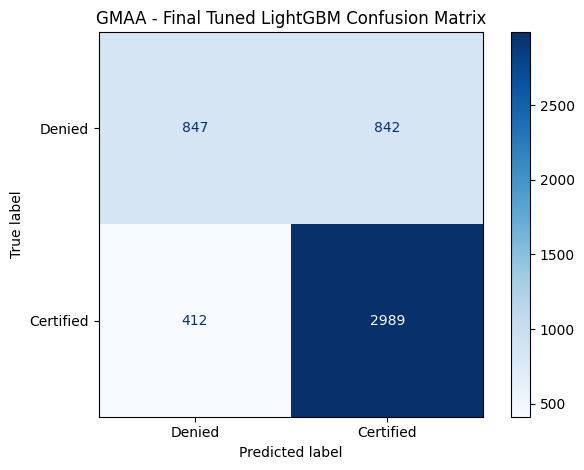

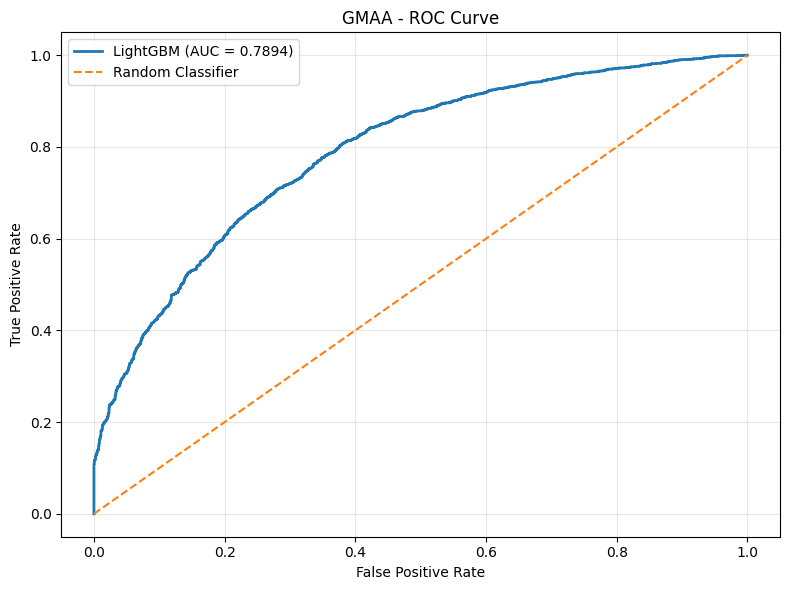

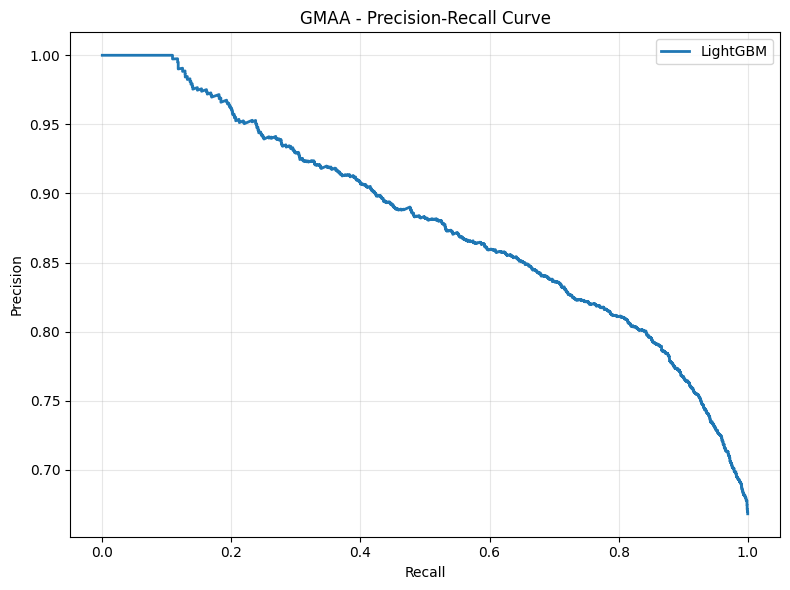

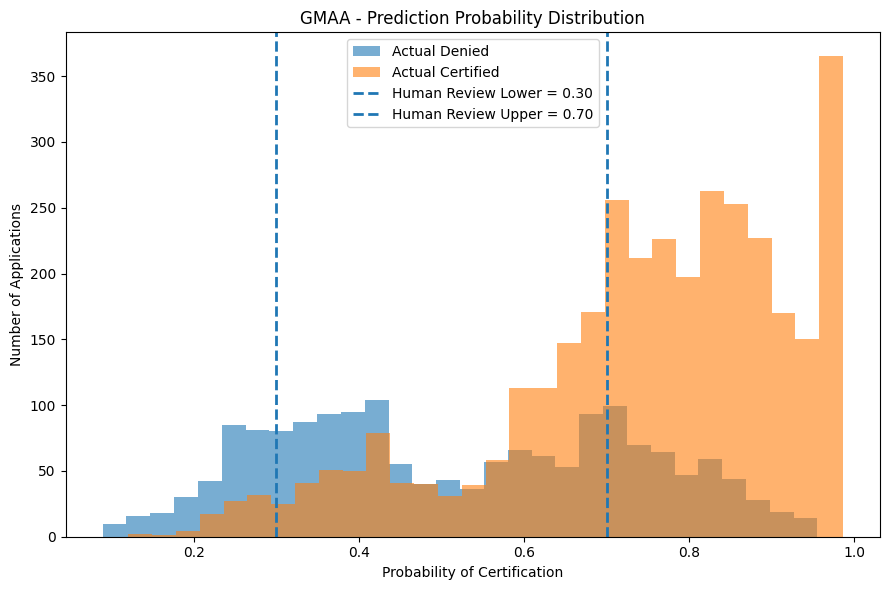


PERFORMANCE VISUALIZATION COMPLETED!


In [33]:
# ============================================================
# GMAA - FINAL MODEL PERFORMANCE VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve
)

print("=" * 70)
print("GMAA - FINAL MODEL PERFORMANCE VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Generate final predictions
# ------------------------------------------------------------

y_pred_final = final_lgbm_pipeline.predict(X_test)
y_prob_final = final_lgbm_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("Number of test samples:", len(y_test))

# ------------------------------------------------------------
# 2. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred_final)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Denied", "Certified"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("GMAA - Final Tuned LightGBM Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. ROC Curve
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_final
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"LightGBM (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GMAA - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Precision-Recall Curve
# ------------------------------------------------------------

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob_final
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label="LightGBM"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GMAA - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Probability Distribution
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.hist(
    y_prob_final[y_test == 0],
    bins=30,
    alpha=0.6,
    label="Actual Denied"
)

plt.hist(
    y_prob_final[y_test == 1],
    bins=30,
    alpha=0.6,
    label="Actual Certified"
)

plt.axvline(
    0.30,
    linestyle="--",
    linewidth=2,
    label="Human Review Lower = 0.30"
)

plt.axvline(
    0.70,
    linestyle="--",
    linewidth=2,
    label="Human Review Upper = 0.70"
)

plt.xlabel("Probability of Certification")
plt.ylabel("Number of Applications")
plt.title("GMAA - Prediction Probability Distribution")
plt.legend()

plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("PERFORMANCE VISUALIZATION COMPLETED!")
print("=" * 70)

In [34]:
# ============================================================
# GMAA - FINAL MODEL CONSISTENCY CHECK
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("GMAA - FINAL MODEL CONSISTENCY CHECK")
print("=" * 70)

# ------------------------------------------------------------
# 1. Generate predictions from final pipeline
# ------------------------------------------------------------

y_pred_check = final_lgbm_pipeline.predict(X_test)
y_prob_check = final_lgbm_pipeline.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# 2. Calculate metrics
# ------------------------------------------------------------

accuracy_check = accuracy_score(y_test, y_pred_check)

precision_check = precision_score(
    y_test,
    y_pred_check,
    pos_label=1
)

recall_check = recall_score(
    y_test,
    y_pred_check,
    pos_label=1
)

f1_check = f1_score(
    y_test,
    y_pred_check,
    pos_label=1
)

roc_auc_check = roc_auc_score(
    y_test,
    y_prob_check
)

cm_check = confusion_matrix(
    y_test,
    y_pred_check
)

# ------------------------------------------------------------
# 3. Display current final model results
# ------------------------------------------------------------

print("\nCURRENT FINAL PIPELINE RESULTS")
print("-" * 50)

print(f"Accuracy  : {accuracy_check:.4f}")
print(f"Precision : {precision_check:.4f}")
print(f"Recall    : {recall_check:.4f}")
print(f"F1 Score  : {f1_check:.4f}")
print(f"ROC-AUC   : {roc_auc_check:.4f}")

print("\nConfusion Matrix:")
print(cm_check)

# ------------------------------------------------------------
# 4. Compare with previously recorded tuned results
# ------------------------------------------------------------

old_accuracy = 0.7472
old_precision = 0.7779
old_recall = 0.8700
old_f1 = 0.8214
old_roc_auc = 0.7797

print("\n" + "=" * 70)
print("COMPARISON WITH PREVIOUSLY RECORDED TUNED MODEL")
print("=" * 70)

print(f"{'Metric':<15} {'Previous':>12} {'Current':>12} {'Difference':>12}")
print("-" * 55)

print(
    f"{'Accuracy':<15} "
    f"{old_accuracy:>12.4f} "
    f"{accuracy_check:>12.4f} "
    f"{accuracy_check-old_accuracy:>12.4f}"
)

print(
    f"{'Precision':<15} "
    f"{old_precision:>12.4f} "
    f"{precision_check:>12.4f} "
    f"{precision_check-old_precision:>12.4f}"
)

print(
    f"{'Recall':<15} "
    f"{old_recall:>12.4f} "
    f"{recall_check:>12.4f} "
    f"{recall_check-old_recall:>12.4f}"
)

print(
    f"{'F1 Score':<15} "
    f"{old_f1:>12.4f} "
    f"{f1_check:>12.4f} "
    f"{f1_check-old_f1:>12.4f}"
)

print(
    f"{'ROC-AUC':<15} "
    f"{old_roc_auc:>12.4f} "
    f"{roc_auc_check:>12.4f} "
    f"{roc_auc_check-old_roc_auc:>12.4f}"
)

# ------------------------------------------------------------
# 5. Compare confusion matrices
# ------------------------------------------------------------

old_cm = np.array([
    [844, 845],
    [442, 2959]
])

print("\n" + "=" * 70)
print("CONFUSION MATRIX COMPARISON")
print("=" * 70)

print("\nPrevious tuned model:")
print(old_cm)

print("\nCurrent final pipeline:")
print(cm_check)

if np.array_equal(old_cm, cm_check):
    print("\n✓ CONFIRMED: Both models produce identical predictions.")
else:
    print("\n⚠ WARNING: Predictions are different.")
    print("We need to identify which pipeline should be treated as final.")

print("\n" + "=" * 70)
print("CONSISTENCY CHECK COMPLETED")
print("=" * 70)

GMAA - FINAL MODEL CONSISTENCY CHECK

CURRENT FINAL PIPELINE RESULTS
--------------------------------------------------
Accuracy  : 0.7536
Precision : 0.7802
Recall    : 0.8789
F1 Score  : 0.8266
ROC-AUC   : 0.7894

Confusion Matrix:
[[ 847  842]
 [ 412 2989]]

COMPARISON WITH PREVIOUSLY RECORDED TUNED MODEL
Metric              Previous      Current   Difference
-------------------------------------------------------
Accuracy              0.7472       0.7536       0.0064
Precision             0.7779       0.7802       0.0023
Recall                0.8700       0.8789       0.0089
F1 Score              0.8214       0.8266       0.0052
ROC-AUC               0.7797       0.7894       0.0097

CONFUSION MATRIX COMPARISON

Previous tuned model:
[[ 844  845]
 [ 442 2959]]

Current final pipeline:
[[ 847  842]
 [ 412 2989]]

⚠ WARNING: Predictions are different.
We need to identify which pipeline should be treated as final.

CONSISTENCY CHECK COMPLETED


In [35]:
# ============================================================
# GMAA - FINAL MODEL PACKAGING
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 70)
print("GMAA - FINAL MODEL PACKAGING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create model directory
# ------------------------------------------------------------

model_dir = "../models"

os.makedirs(model_dir, exist_ok=True)

print(f"Model directory ready: {os.path.abspath(model_dir)}")

# ------------------------------------------------------------
# 2. Save final LightGBM pipeline
# ------------------------------------------------------------

model_path = os.path.join(
    model_dir,
    "gmaa_final_lightgbm_pipeline.joblib"
)

joblib.dump(
    final_lgbm_pipeline,
    model_path
)

print("\n✓ Final LightGBM pipeline saved")
print("Path:", os.path.abspath(model_path))

# ------------------------------------------------------------
# 3. Generate final predictions
# ------------------------------------------------------------

y_pred_final = final_lgbm_pipeline.predict(X_test)

y_prob_final = final_lgbm_pipeline.predict_proba(
    X_test
)[:, 1]

# ------------------------------------------------------------
# 4. Calculate final metrics
# ------------------------------------------------------------

final_accuracy = accuracy_score(
    y_test,
    y_pred_final
)

final_precision = precision_score(
    y_test,
    y_pred_final,
    pos_label=1
)

final_recall = recall_score(
    y_test,
    y_pred_final,
    pos_label=1
)

final_f1 = f1_score(
    y_test,
    y_pred_final,
    pos_label=1
)

final_roc_auc = roc_auc_score(
    y_test,
    y_prob_final
)

# ------------------------------------------------------------
# 5. GMAA decision configuration
# ------------------------------------------------------------

HUMAN_REVIEW_LOWER = 0.30
HUMAN_REVIEW_UPPER = 0.70

# ------------------------------------------------------------
# 6. Model metadata
# ------------------------------------------------------------

metadata = {
    "project": "GMAA",
    "system_name": "GMAA - Global Mobility Application Assessment",
    "model": "LightGBM",
    "model_type": "Binary Classification",
    "target": "case_status",

    "classes": {
        "0": "Denied",
        "1": "Certified"
    },

    "test_samples": int(len(y_test)),

    "metrics": {
        "accuracy": float(final_accuracy),
        "precision": float(final_precision),
        "recall": float(final_recall),
        "f1_score": float(final_f1),
        "roc_auc": float(final_roc_auc)
    },

    "human_review": {
        "lower_threshold": HUMAN_REVIEW_LOWER,
        "upper_threshold": HUMAN_REVIEW_UPPER
    },

    "decision_rules": {
        "probability_below_0_30": "AUTOMATIC - DENIED",
        "probability_between_0_30_and_0_70": "HUMAN REVIEW",
        "probability_above_0_70": "AUTOMATIC - CERTIFIED"
    },

    "explainability": {
        "method": "SHAP",
        "explainer": "TreeExplainer"
    },

    "fairness": {
        "analysis": [
            "job experience",
            "education",
            "continent",
            "region of employment"
        ]
    }
}

# ------------------------------------------------------------
# 7. Save metadata
# ------------------------------------------------------------

metadata_path = os.path.join(
    model_dir,
    "gmaa_model_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

print("\n✓ Model metadata saved")
print("Path:", os.path.abspath(metadata_path))

# ------------------------------------------------------------
# 8. Save final test predictions
# ------------------------------------------------------------

results_df = pd.DataFrame({
    "actual_status": y_test.values,
    "predicted_status": y_pred_final,
    "probability_certified": y_prob_final
})

results_df["confidence"] = np.maximum(
    results_df["probability_certified"],
    1 - results_df["probability_certified"]
)

# GMAA decision engine
results_df["gmaa_decision"] = np.where(
    results_df["probability_certified"] < HUMAN_REVIEW_LOWER,
    "AUTOMATIC - DENIED",
    np.where(
        results_df["probability_certified"] > HUMAN_REVIEW_UPPER,
        "AUTOMATIC - CERTIFIED",
        "HUMAN REVIEW"
    )
)

results_path = os.path.join(
    model_dir,
    "gmaa_final_test_predictions.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\n✓ Final test predictions saved")
print("Path:", os.path.abspath(results_path))

# ------------------------------------------------------------
# 9. Final decision distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL GMAA DECISION DISTRIBUTION")
print("=" * 70)

decision_counts = results_df["gmaa_decision"].value_counts()

print(decision_counts)

print("\nDecision percentages:")

decision_percentages = (
    results_df["gmaa_decision"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(decision_percentages)

# ------------------------------------------------------------
# 10. Final official metrics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OFFICIAL FINAL MODEL RESULTS")
print("=" * 70)

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")
print(f"ROC-AUC   : {final_roc_auc:.4f}")

print("\nHuman Review Threshold:")
print(f"{HUMAN_REVIEW_LOWER:.2f} - {HUMAN_REVIEW_UPPER:.2f}")

print("\n" + "=" * 70)
print("GMAA FINAL MODEL PACKAGED SUCCESSFULLY!")
print("=" * 70)

GMAA - FINAL MODEL PACKAGING
Model directory ready: c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\models

✓ Final LightGBM pipeline saved
Path: c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\models\gmaa_final_lightgbm_pipeline.joblib

✓ Model metadata saved
Path: c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\models\gmaa_model_metadata.json

✓ Final test predictions saved
Path: c:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\models\gmaa_final_test_predictions.csv

FINAL GMAA DECISION DISTRIBUTION
gmaa_decision
AUTOMATIC - CERTIFIED    2728
HUMAN REVIEW             1964
AUTOMATIC - DENIED        398
Name: count, dtype: int64

Decision percentages:
gmaa_decision
AUTOMATIC - CERTIFIED    53.60
HUMAN REVIEW             38.59
AUTOMATIC - DENIED        7.82
Name: proportion, dtype: float64

OFFICIAL FINAL MODEL RESULTS
Accuracy  : 0.7536
Precision : 0.7802
Recall    : 0.8789
F1 Score  : 0.8266
ROC-AUC   : 0.7894

Human Review Threshold:
0.30 - 0.70

GMAA FINAL MODEL PACKAGED SUCCESSFULLY!


In [36]:
# ============================================================
# GMAA - SAVED MODEL RELOAD & DEPLOYMENT READINESS TEST
# ============================================================

import os
import json
import joblib
import pandas as pd
import numpy as np

print("=" * 70)
print("GMAA - SAVED MODEL RELOAD TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define paths
# ------------------------------------------------------------

MODEL_PATH = r"C:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\models\gmaa_final_lightgbm_pipeline.joblib"
METADATA_PATH = r"C:\Users\Kommu\OneDrive\Pictures\Desktop\GMAA\models\gmaa_model_metadata.json"

# ------------------------------------------------------------
# 2. Check files
# ------------------------------------------------------------

print("\nChecking saved files...")

if os.path.exists(MODEL_PATH):
    print("✓ Model file found")
else:
    raise FileNotFoundError("Final model file not found!")

if os.path.exists(METADATA_PATH):
    print("✓ Metadata file found")
else:
    raise FileNotFoundError("Metadata file not found!")

# ------------------------------------------------------------
# 3. Load model
# ------------------------------------------------------------

loaded_model = joblib.load(MODEL_PATH)

print("\n✓ Final LightGBM pipeline loaded successfully!")
print("\nLoaded model:")
print(loaded_model)

# ------------------------------------------------------------
# 4. Load metadata
# ------------------------------------------------------------

with open(METADATA_PATH, "r") as f:
    metadata = json.load(f)

print("\n✓ Model metadata loaded successfully!")

print("\nMetadata:")
print(json.dumps(metadata, indent=2))

# ------------------------------------------------------------
# 5. Create a sample application
# ------------------------------------------------------------

sample_application = pd.DataFrame([{
    "continent": "Asia",
    "education_of_employee": "Master's",
    "has_job_experience": "Y",
    "requires_job_training": "N",
    "no_of_employees": 3000,
    "yr_of_estab": 2005,
    "region_of_employment": "South",
    "prevailing_wage": 60000,
    "unit_of_wage": "Year",
    "full_time_position": "Y"
}])

print("\n" + "=" * 70)
print("SAMPLE APPLICATION")
print("=" * 70)

print(sample_application.to_string(index=False))

# ------------------------------------------------------------
# 6. Generate prediction
# ------------------------------------------------------------

probability = loaded_model.predict_proba(sample_application)[0, 1]

prediction = (
    "Certified"
    if probability >= 0.50
    else "Denied"
)

confidence = max(probability, 1 - probability)

# ------------------------------------------------------------
# 7. GMAA decision engine
# ------------------------------------------------------------

if probability > 0.70:

    gmaa_decision = "AUTOMATIC - CERTIFIED"
    reason = (
        "The model is sufficiently confident that "
        "the application should be Certified."
    )

elif probability < 0.30:

    gmaa_decision = "AUTOMATIC - DENIED"
    reason = (
        "The model is sufficiently confident that "
        "the application should be Denied."
    )

else:

    gmaa_decision = "HUMAN REVIEW"
    reason = (
        "The prediction falls within the human review range "
        "(0.30 - 0.70). Manual review is required."
    )

# ------------------------------------------------------------
# 8. Final result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GMAA DEPLOYMENT READINESS TEST RESULT")
print("=" * 70)

print(f"Prediction          : {prediction}")
print(f"Probability         : {probability:.4f}")
print(f"Probability (%)     : {probability * 100:.2f}%")
print(f"Confidence          : {confidence:.4f}")
print(f"Confidence (%)      : {confidence * 100:.2f}%")
print(f"GMAA Decision       : {gmaa_decision}")
print(f"Reason              : {reason}")

print("\n" + "=" * 70)
print("✓ SAVED MODEL RELOAD TEST COMPLETED SUCCESSFULLY!")
print("=" * 70)

GMAA - SAVED MODEL RELOAD TEST

Checking saved files...
✓ Model file found
✓ Metadata file found

✓ Final LightGBM pipeline loaded successfully!

Loaded model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['no_of_employees',
                                                   'yr_of_estab',
                                                   'prevailing_wage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['continent',
                                                   'education_of_employee',
                                                   'has_job_experience',
                                                   'requires_job_training',
   